In [2]:
import os
import time
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
from sklearn.linear_model import LinearRegression

In [3]:
def build_master_dataframe(directory_path):
    start_time = time.time()
    master_rows = []

    for filename in os.listdir(directory_path):
        if filename.endswith(".parquet"):
            file_path = os.path.join(directory_path, filename)
            df = pd.read_parquet(file_path)

            country_name = filename.split("_")[0]
            df = df[df["Year"] >= 2015].copy()
            df = df.ffill().bfill()

            # Eliminar columna 'house_price' si existe
            if "house_price" in df.columns:
                df.drop(columns=["house_price"], inplace=True)

            macro_columns = [col for col in df.columns if col != "Year"]

            # Aplicar diferenciación a cada columna macroeconómica
            for col in macro_columns:
                df[col] = df[col].diff().fillna(0)

            country_features = {"Country": country_name}

            for col in macro_columns:
                series = df[col].values
                years = df["Year"].values.reshape(-1, 1)

                country_features[f"{col}_mean"] = np.mean(series)
                country_features[f"{col}_median"] = np.median(series)
                country_features[f"{col}_std"] = np.std(series)
                country_features[f"{col}_cv"] = np.std(series) / np.mean(series) if np.mean(series) != 0 else 0
                country_features[f"{col}_min"] = np.min(series)
                country_features[f"{col}_max"] = np.max(series)
                country_features[f"{col}_last"] = series[-1]
                country_features[f"{col}_growth"] = (series[-1] - series[0]) / series[0] if series[0] != 0 else 0

                if np.std(series) < 1e-8:
                    country_features[f"{col}_skew"] = 0
                    country_features[f"{col}_kurtosis"] = 0
                else:
                    country_features[f"{col}_skew"] = skew(series)
                    country_features[f"{col}_kurtosis"] = kurtosis(series)

                try:
                    model = LinearRegression().fit(years, series)
                    country_features[f"{col}_trend"] = model.coef_[0]
                except:
                    country_features[f"{col}_trend"] = np.nan

            master_rows.append(country_features)

    master_df = pd.DataFrame(master_rows)
    end_time = time.time()
    print(f"Time taken to perform feature engineering: {round(end_time - start_time, 2)} sec.")
    return master_df


In [4]:
df_example = pd.read_parquet('../data/by_country/Australia_macro_profile.parquet')
df_example.head()

,Year,labor_force,livestock_prod,agr_land,urban_pop,gov_exp,reserves,investment,cpi,gdp,priv_cred,unemployment,house_price,rule_of_law_df,share_of_industry_df,tax_revenue_df,inflation_df,edu_spending_df,govermment_effective_df
0,2007,NaN,NaN,NaN,NaN,NaN,NaN,78.7775,NaN,283.4875,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2008,NaN,NaN,NaN,NaN,NaN,NaN,87.3575,NaN,309.1825,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2009,NaN,NaN,NaN,NaN,NaN,NaN,86.2500,NaN,315.9400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2010,NaN,NaN,NaN,NaN,NaN,NaN,89.9575,NaN,341.5600,NaN,NaN,100.000,NaN,NaN,NaN,NaN,NaN,NaN
4,2011,NaN,NaN,NaN,NaN,NaN,NaN,97.0800,NaN,367.2525,NaN,NaN,97.845,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df_filter = df_example[df_example["Year"] >= 2015].copy()

In [7]:
df_filter = df_filter.ffill()

In [8]:
df_filter = df_filter.bfill()

In [9]:
df_filter

,Year,labor_force,livestock_prod,agr_land,urban_pop,gov_exp,reserves,investment,cpi,gdp,priv_cred,unemployment,house_price,rule_of_law_df,share_of_industry_df,tax_revenue_df,inflation_df,edu_spending_df,govermment_effective_df
8,2015,12.73,102.4,45.31,85.80,80.1975,62.596667,105.8950,107.675,409.8350,2207.458333,5.713333,123.6450,1.72,23.47,21.87,1.9,5.46,1.53
9,2016,12.73,96.8,44.54,85.80,85.2900,60.568333,104.4575,109.050,424.6600,2367.798333,5.713333,130.4450,1.72,23.47,22.26,1.9,5.43,1.53
10,2017,13.01,91.0,48.34,85.90,89.7925,73.416667,109.4400,111.175,450.3775,2493.594167,5.606667,141.3350,1.65,23.47,22.09,1.9,5.32,1.50
11,2018,13.31,97.2,46.66,86.01,95.3525,71.986667,114.2550,113.300,473.9000,2550.039167,5.306667,139.3050,1.67,24.12,23.18,1.9,5.41,1.56
12,2019,13.59,97.7,47.12,86.12,103.7050,73.037500,113.9775,115.125,498.6975,2589.645000,5.165000,133.6400,1.69,25.27,23.38,1.6,5.51,1.54
13,2020,13.58,90.6,46.25,86.24,113.1950,65.861667,111.7475,116.100,494.0275,2656.729167,6.441667,140.8525,1.62,25.39,22.56,0.8,5.38,1.57
14,2021,13.80,87.9,47.26,86.36,122.0550,68.871667,127.3975,119.425,550.6875,2760.232500,5.138333,165.3925,1.64,25.42,23.03,2.9,5.33,1.47
15,2022,14.07,87.5,47.26,86.49,133.1300,81.175833,142.0275,127.300,620.9125,2991.540000,3.725833,179.0200,1.51,27.48,23.60,6.6,5.21,1.53
16,2023,14.50,87.5,47.26,86.62,142.2425,90.190000,157.1425,134.425,655.5775,3173.511667,3.686667,178.6500,1.52,27.65,23.60,5.6,5.21,1.59
17,2024,14.50,87.5,47.26,86.62,154.9175,94.169167,166.4175,138.675,680.3275,3340.351667,3.686667,192.5275,1.52,25.97,23.60,3.2,5.21,1.59


In [10]:
import matplotlib.pyplot as plt

def plot_column_timeseries(df, column_name, n=None):
    """
    Grafica una serie temporal de una columna específica de un DataFrame.

    Parámetros:
    - df: DataFrame que contiene los datos.
    - column_name: nombre de la columna a graficar.
    - n: número de puntos a graficar (opcional). Si es None, grafica todo.
    """
    if column_name not in df.columns:
        print(f"La columna '{column_name}' no existe en el DataFrame.")
        return

    # Filtrar los datos si se especifica n
    data = df.copy()
    if n is not None:
        data = data.head(n)

    plt.figure(figsize=(10, 5))
    plt.plot(data["Year"], data[column_name], marker='o', linestyle='-')
    plt.title(f"Serie temporal de '{column_name}'")
    plt.xlabel("Año")
    plt.ylabel(column_name)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

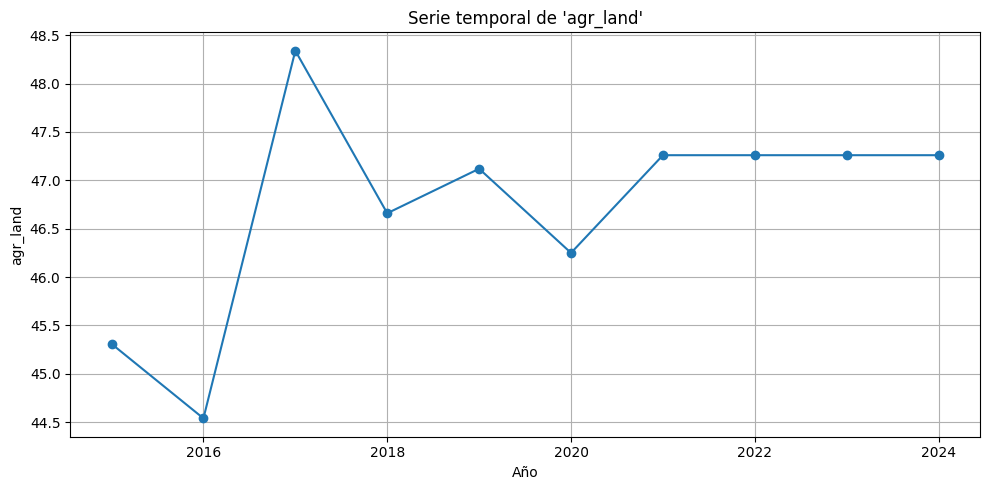

In [13]:
plot_column_timeseries(df_filter, "agr_land")

In [14]:
macro_cols = [col for col in df_filter.columns if col != "Year"]
df_diff = df_filter.copy()
df_diff[macro_cols] = df_diff[macro_cols].diff().fillna(0)

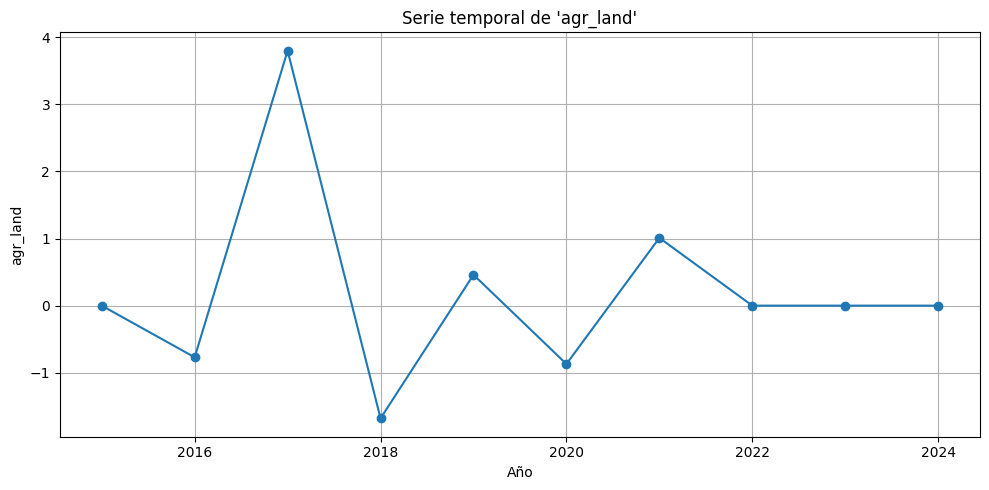

In [15]:
plot_column_timeseries(df_diff, "agr_land")

In [16]:
df_diff_2 = df_diff.copy()
df_diff_2[macro_cols] = df_diff_2[macro_cols].diff().fillna(0)

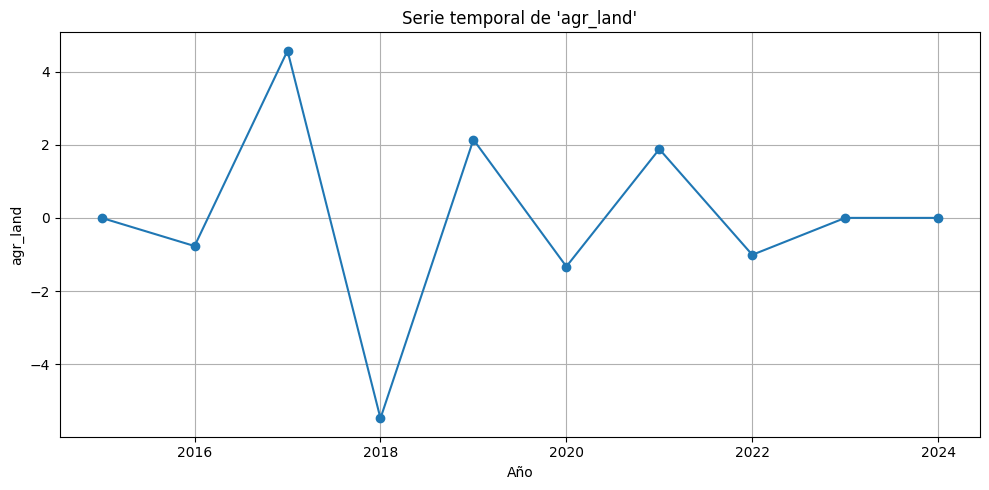

In [17]:
plot_column_timeseries(df_diff_2, "agr_land")

In [18]:
master_df = build_master_dataframe("../data/by_country/")

Time taken to perform feature engineering: 3.27 sec.


In [20]:
master_df

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective_df_median,govermment_effective_df_std,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_last,govermment_effective_df_growth,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,Australia,0.177,0.245,0.154858,0.874904,-0.01,0.43,0.0,0,-5.521361e-02,...,0.000,0.047582,7.930252,-0.10,0.06,0.0,0,-0.714489,0.008940,0.002667
1,Austria,0.026,0.025,0.029732,1.143544,-0.02,0.07,0.0,0,1.397090e-01,...,0.000,0.064529,-4.609219,-0.13,0.12,0.0,0,0.178013,0.092429,-0.008364
2,Belgium,0.042,0.050,0.042379,1.009030,-0.02,0.11,0.0,0,3.436990e-02,...,-0.010,0.090465,-2.512930,-0.19,0.14,0.0,0,-0.036566,-0.315602,0.002061
3,Brazil,0.490,0.600,2.586797,5.279178,-6.21,4.11,0.0,0,-1.395227e+00,...,-0.010,0.137695,-4.589844,-0.24,0.29,0.0,0,0.712911,0.705002,0.000848
4,Bulgaria,-0.018,-0.015,0.057585,-3.199151,-0.12,0.09,0.0,0,1.293317e-01,...,0.000,0.162247,-40.561681,-0.38,0.32,0.0,0,-0.457424,1.491768,0.008242
5,Canada,0.226,0.235,0.291280,1.288849,-0.29,0.76,0.0,0,4.958420e-02,...,0.000,0.059800,-2.718167,-0.14,0.08,0.0,0,-0.442080,-0.304311,-0.003152
6,Chile,0.120,0.170,0.228123,1.901023,-0.40,0.50,0.0,0,-6.921108e-01,...,-0.010,0.088933,-8.084778,-0.15,0.17,0.0,0,0.460112,-0.214137,0.002000
7,Colombia,0.232,0.210,0.256780,1.106811,-0.09,0.77,0.0,0,6.087500e-01,...,0.000,0.054991,9.165151,-0.09,0.15,0.0,0,1.262546,2.630952,-0.002909
8,Croatia,-0.006,0.000,0.015620,-2.603417,-0.04,0.01,0.0,0,-8.374871e-01,...,0.000,0.067594,2.330841,-0.05,0.13,0.0,0,0.555008,-1.311189,0.005758
9,Cyprus,0.010,0.010,0.007746,0.774597,0.00,0.02,0.0,0,3.963991e-15,...,0.000,0.062841,-3.307425,-0.14,0.08,0.0,0,-0.675969,-0.296866,-0.001030


In [31]:
def eliminar_columnas_casi_cero(df, umbral=1e-6):
    """
    Elimina columnas numéricas que contienen solo ceros o valores muy cercanos a cero.
    """
    columnas_validas = []

    for col in df.columns:
        serie = df[col].dropna()

        if pd.api.types.is_numeric_dtype(serie):
            # Verifica si todos los valores son cero o casi cero
            todos_ceros = all(val == 0.0 for val in serie)
            todos_casi_cero = all(abs(val) <= umbral for val in serie)

            if not (todos_ceros or todos_casi_cero):
                columnas_validas.append(col)
        else:
            columnas_validas.append(col)  # conservar columnas no numéricas

    return df[columnas_validas].copy()

In [32]:
master_df_without_zero = eliminar_columnas_casi_cero(master_df)

In [33]:
master_df_without_zero

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_skew,labor_force_kurtosis,...,edu_spending_df_trend,govermment_effective_df_mean,govermment_effective_df_median,govermment_effective_df_std,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,Australia,0.177,0.245,0.154858,0.874904,-0.01,0.43,0.0,-5.521361e-02,-1.470372,...,-0.002970,0.006,0.000,0.047582,7.930252,-0.10,0.06,-0.714489,0.008940,0.002667
1,Austria,0.026,0.025,0.029732,1.143544,-0.02,0.07,0.0,1.397090e-01,-1.244774,...,-0.016061,-0.014,0.000,0.064529,-4.609219,-0.13,0.12,0.178013,0.092429,-0.008364
2,Belgium,0.042,0.050,0.042379,1.009030,-0.02,0.11,0.0,3.436990e-02,-1.356918,...,-0.003455,-0.036,-0.010,0.090465,-2.512930,-0.19,0.14,-0.036566,-0.315602,0.002061
3,Brazil,0.490,0.600,2.586797,5.279178,-6.21,4.11,0.0,-1.395227e+00,1.933179,...,-0.004364,-0.030,-0.010,0.137695,-4.589844,-0.24,0.29,0.712911,0.705002,0.000848
4,Bulgaria,-0.018,-0.015,0.057585,-3.199151,-0.12,0.09,0.0,1.293317e-01,-0.434776,...,0.006667,-0.004,0.000,0.162247,-40.561681,-0.38,0.32,-0.457424,1.491768,0.008242
5,Canada,0.226,0.235,0.291280,1.288849,-0.29,0.76,0.0,4.958420e-02,-0.673726,...,-0.025939,-0.022,0.000,0.059800,-2.718167,-0.14,0.08,-0.442080,-0.304311,-0.003152
6,Chile,0.120,0.170,0.228123,1.901023,-0.40,0.50,0.0,-6.921108e-01,0.541125,...,-0.034909,-0.011,-0.010,0.088933,-8.084778,-0.15,0.17,0.460112,-0.214137,0.002000
7,Colombia,0.232,0.210,0.256780,1.106811,-0.09,0.77,0.0,6.087500e-01,-0.538067,...,-0.016364,0.006,0.000,0.054991,9.165151,-0.09,0.15,1.262546,2.630952,-0.002909
8,Croatia,-0.006,0.000,0.015620,-2.603417,-0.04,0.01,0.0,-8.374871e-01,-0.289170,...,0.030364,0.029,0.000,0.067594,2.330841,-0.05,0.13,0.555008,-1.311189,0.005758
9,Cyprus,0.010,0.010,0.007746,0.774597,0.00,0.02,0.0,3.963991e-15,-1.333333,...,0.026788,-0.019,0.000,0.062841,-3.307425,-0.14,0.08,-0.675969,-0.296866,-0.001030


In [38]:
def eliminar_columnas_con_muchos_ceros(df, porcentaje_umbral=0.8):
    """
    Elimina columnas numéricas donde más del porcentaje_umbral de valores son ceros exactos.
    
    Parámetros:
    - df: DataFrame original.
    - porcentaje_umbral: proporción máxima permitida de ceros (por defecto 0.8 = 80%)
    
    Retorna:
    - DataFrame sin las columnas que cumplen la condición.
    """
    columnas_validas = []

    for col in df.columns:
        serie = df[col]

        if pd.api.types.is_numeric_dtype(serie):
            total = len(serie.dropna())
            ceros = (serie == 0).sum()

            if total == 0 or (ceros / total) <= porcentaje_umbral:
                columnas_validas.append(col)
        else:
            columnas_validas.append(col)  # conservar columnas no numéricas

    return df[columnas_validas].copy()

In [39]:
master_df_without_zero = eliminar_columnas_con_muchos_ceros(master_df_without_zero)

In [40]:
master_df_without_zero

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_skew,labor_force_kurtosis,labor_force_trend,...,edu_spending_df_trend,govermment_effective_df_mean,govermment_effective_df_median,govermment_effective_df_std,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,Australia,0.177,0.245,0.154858,0.874904,-0.01,0.43,-5.521361e-02,-1.470372,0.014727,...,-0.002970,0.006,0.000,0.047582,7.930252,-0.10,0.06,-0.714489,0.008940,0.002667
1,Austria,0.026,0.025,0.029732,1.143544,-0.02,0.07,1.397090e-01,-1.244774,0.004121,...,-0.016061,-0.014,0.000,0.064529,-4.609219,-0.13,0.12,0.178013,0.092429,-0.008364
2,Belgium,0.042,0.050,0.042379,1.009030,-0.02,0.11,3.436990e-02,-1.356918,0.003152,...,-0.003455,-0.036,-0.010,0.090465,-2.512930,-0.19,0.14,-0.036566,-0.315602,0.002061
3,Brazil,0.490,0.600,2.586797,5.279178,-6.21,4.11,-1.395227e+00,1.933179,0.020121,...,-0.004364,-0.030,-0.010,0.137695,-4.589844,-0.24,0.29,0.712911,0.705002,0.000848
4,Bulgaria,-0.018,-0.015,0.057585,-3.199151,-0.12,0.09,1.293317e-01,-0.434776,-0.010182,...,0.006667,-0.004,0.000,0.162247,-40.561681,-0.38,0.32,-0.457424,1.491768,0.008242
5,Canada,0.226,0.235,0.291280,1.288849,-0.29,0.76,4.958420e-02,-0.673726,0.037455,...,-0.025939,-0.022,0.000,0.059800,-2.718167,-0.14,0.08,-0.442080,-0.304311,-0.003152
6,Chile,0.120,0.170,0.228123,1.901023,-0.40,0.50,-6.921108e-01,0.541125,0.019030,...,-0.034909,-0.011,-0.010,0.088933,-8.084778,-0.15,0.17,0.460112,-0.214137,0.002000
7,Colombia,0.232,0.210,0.256780,1.106811,-0.09,0.77,6.087500e-01,-0.538067,0.011394,...,-0.016364,0.006,0.000,0.054991,9.165151,-0.09,0.15,1.262546,2.630952,-0.002909
8,Croatia,-0.006,0.000,0.015620,-2.603417,-0.04,0.01,-8.374871e-01,-0.289170,0.002303,...,0.030364,0.029,0.000,0.067594,2.330841,-0.05,0.13,0.555008,-1.311189,0.005758
9,Cyprus,0.010,0.010,0.007746,0.774597,0.00,0.02,3.963991e-15,-1.333333,0.000727,...,0.026788,-0.019,0.000,0.062841,-3.307425,-0.14,0.08,-0.675969,-0.296866,-0.001030


In [41]:
master_df_without_zero.to_parquet('../data/diff_then_one_point_countries_then_delete_zeros.parquet')

In [42]:
def adaptive_log_transform(df):
    """
    Applies logarithmic transformation to numeric columns with outliers,
    choosing between log(x) and log1p(x) based on the presence of near-zero values.

    Parameters:
    ----------
    df : pandas.DataFrame
        The input DataFrame containing numeric and non-numeric columns.

    Returns:
    -------
    transformed_df : pandas.DataFrame
        A copy of the original DataFrame with selected numeric columns log-transformed.
        Columns are transformed only if:
            - They contain outliers (based on IQR method).
            - All values are strictly positive.
            - If values are close to zero, log1p(x) is used instead of log(x).
    """

    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
    transformed_df = df.copy()

    for col in numeric_cols:
        series = df[col]

        # Check for outliers using IQR
        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)
        IQR = Q3 - Q1
        outliers = series[(series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)]

        # Proceed only if outliers exist and all values are positive
        if outliers.shape[0] > 0 and (series > 0).all():
            min_val = series.min()

            # Use log1p if values are close to zero
            if min_val < 1:
                transformed_df[col] = np.log1p(series)
                print(f"Applied log1p transformation to column: {col}")
            else:
                transformed_df[col] = np.log(series)
                print(f"Applied log transformation to column: {col}")

    return transformed_df

In [43]:
master_df_without_zero_log = adaptive_log_transform(master_df_without_zero)

Applied log1p transformation to column: labor_force_std
Applied log1p transformation to column: labor_force_max
Applied log1p transformation to column: livestock_prod_std
Applied log1p transformation to column: gov_exp_mean
Applied log1p transformation to column: gov_exp_median
Applied log1p transformation to column: gov_exp_std
Applied log1p transformation to column: gov_exp_cv
Applied log1p transformation to column: gov_exp_max
Applied log1p transformation to column: gov_exp_trend
Applied log1p transformation to column: reserves_std
Applied log1p transformation to column: reserves_max
Applied log1p transformation to column: investment_mean
Applied log1p transformation to column: investment_median
Applied log1p transformation to column: investment_std
Applied log1p transformation to column: investment_cv
Applied log1p transformation to column: investment_max
Applied log1p transformation to column: cpi_median
Applied log transformation to column: cpi_std
Applied log transformation to c

In [44]:
def detect_top_outliers(df, top_n=5):
    # Select only numerical columns
    numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns

    outlier_counts = {}

    # Count outliers per column using IQR method
    for col in numeric_columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
        outlier_counts[col] = outliers.shape[0]

    # Sort columns by number of outliers (descending)
    sorted_outliers = dict(sorted(outlier_counts.items(), key=lambda item: item[1], reverse=True))

    print("Number of outliers per column (sorted):\n")
    for col, count in sorted_outliers.items():
        print(f"{col}: {count}")

    # Plot boxplots for top N columns with most outliers
    top_columns = list(sorted_outliers.keys())[:top_n]

    plt.figure(figsize=(15, top_n * 2))
    for i, col in enumerate(top_columns, 1):
        plt.subplot(top_n, 1, i)
        sns.boxplot(x=df[col], color='salmon')
        plt.title(f'Boxplot of {col}', fontsize=11)
        plt.tight_layout()

    plt.show()

Number of outliers per column (sorted):

rule_of_law_df_median: 21
govermment_effective_df_median: 18
tax_revenue_df_median: 17
agr_land_median: 16
labor_force_cv: 14
urban_pop_kurtosis: 14
reserves_trend: 13
unemployment_cv: 13
inflation_df_median: 13
edu_spending_df_median: 13
priv_cred_cv: 12
priv_cred_last: 12
labor_force_trend: 11
agr_land_trend: 11
urban_pop_cv: 11
investment_last: 11
priv_cred_min: 11
priv_cred_trend: 11
share_of_industry_df_median: 11
labor_force_min: 10
livestock_prod_cv: 10
gov_exp_last: 10
investment_min: 10
investment_trend: 10
priv_cred_mean: 10
rule_of_law_df_cv: 10
labor_force_mean: 9
gdp_min: 9
priv_cred_median: 9
priv_cred_max: 9
share_of_industry_df_cv: 9
livestock_prod_median: 8
agr_land_cv: 8
gov_exp_trend: 8
reserves_median: 8
reserves_min: 8
reserves_last: 8
edu_spending_df_cv: 8
labor_force_median: 7
labor_force_std: 7
reserves_cv: 7
agr_land_mean: 6
agr_land_max: 6
urban_pop_skew: 6
reserves_mean: 6
unemployment_max: 6
tax_revenue_df_cv: 6
infla

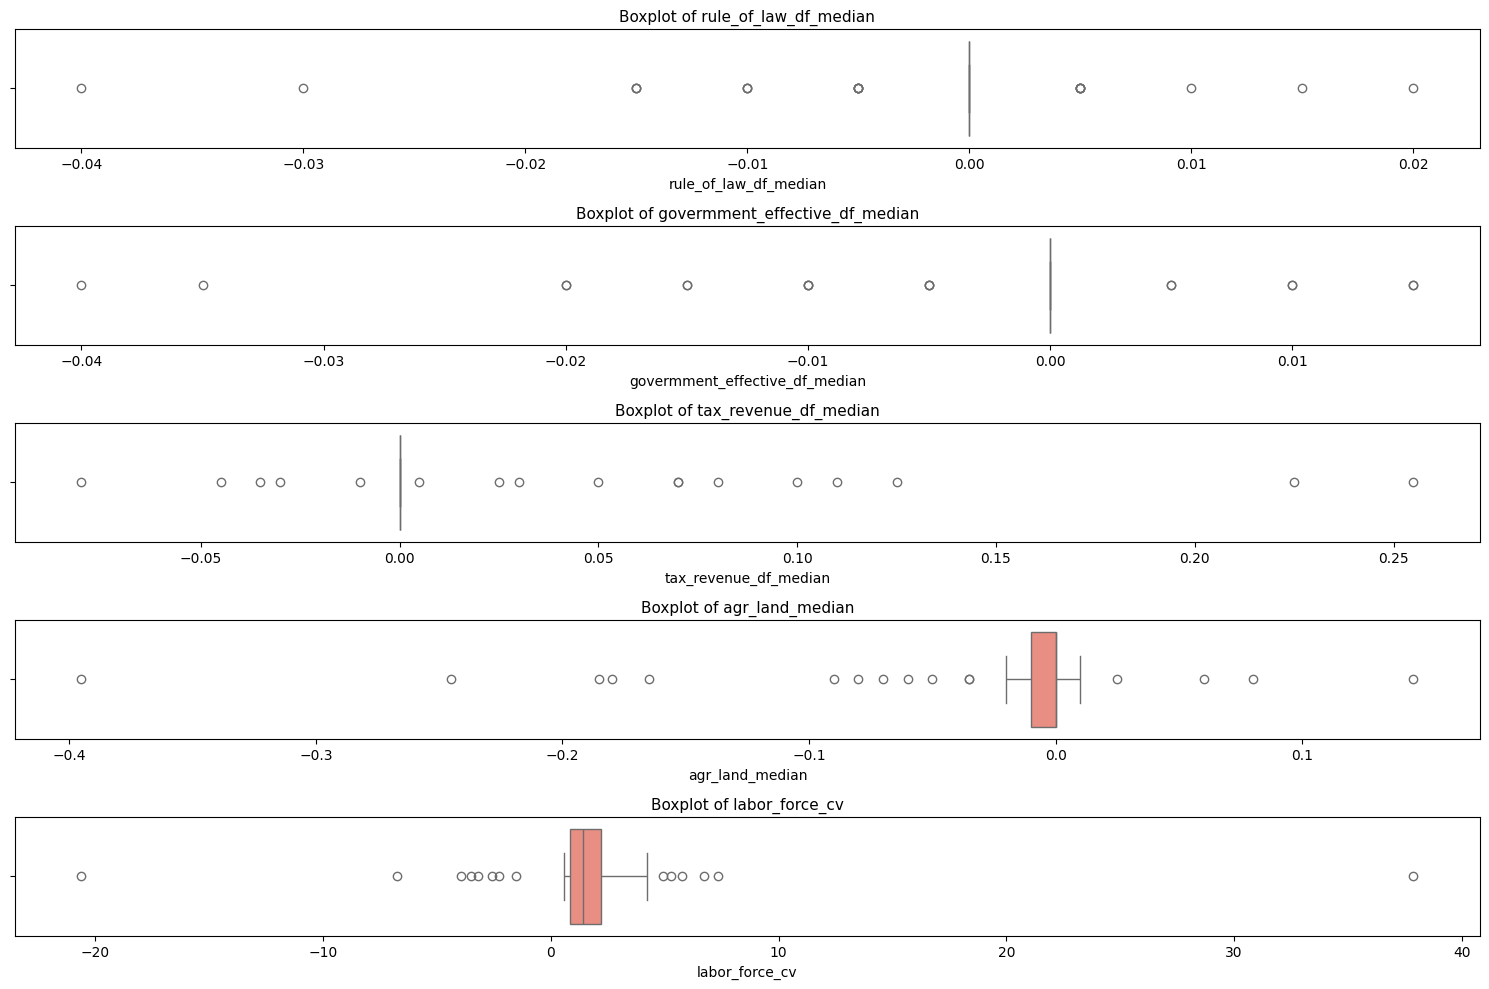

In [45]:
detect_top_outliers(master_df_without_zero_log)

In [46]:
from sklearn.preprocessing import StandardScaler
from scipy.stats.mstats import winsorize

In [47]:
def apply_standard_scaler(original_df, log_transformed_df):
    """
    Applies StandardScaler to numeric columns that were not log-transformed.

    Parameters:
    ----------
    original_df : pandas.DataFrame
        The original DataFrame before any transformations.

    log_transformed_df : pandas.DataFrame
        The DataFrame after applying log transformations to selected columns.

    Returns:
    -------
    scaled_df : pandas.DataFrame
        A copy of the log_transformed_df with StandardScaler applied to numeric columns
        that were not previously log-transformed.
    """

    # Identify numeric columns in both DataFrames
    original_numeric = original_df.select_dtypes(include=['float64', 'int64']).columns
    transformed_numeric = log_transformed_df.select_dtypes(include=['float64', 'int64']).columns

    # Columns that were not transformed (same values as original)
    untouched_columns = [
        col for col in original_numeric
        if col in transformed_numeric and original_df[col].equals(log_transformed_df[col])
    ]

    # Apply StandardScaler to untouched numeric columns
    scaler = StandardScaler()
    scaled_df = log_transformed_df.copy()
    scaled_df[untouched_columns] = scaler.fit_transform(original_df[untouched_columns])

    print(f"Applied StandardScaler to columns: {untouched_columns}")
    return scaled_df, untouched_columns

In [49]:
master_df_without_zero_scaler, untouched_colums = apply_standard_scaler(master_df_without_zero, master_df_without_zero_log)

Applied StandardScaler to columns: ['labor_force_mean', 'labor_force_median', 'labor_force_cv', 'labor_force_min', 'labor_force_skew', 'labor_force_kurtosis', 'labor_force_trend', 'livestock_prod_mean', 'livestock_prod_median', 'livestock_prod_cv', 'livestock_prod_min', 'livestock_prod_max', 'livestock_prod_skew', 'livestock_prod_kurtosis', 'livestock_prod_trend', 'agr_land_mean', 'agr_land_median', 'agr_land_std', 'agr_land_cv', 'agr_land_min', 'agr_land_max', 'agr_land_skew', 'agr_land_kurtosis', 'agr_land_trend', 'urban_pop_mean', 'urban_pop_median', 'urban_pop_std', 'urban_pop_cv', 'urban_pop_max', 'urban_pop_skew', 'urban_pop_kurtosis', 'urban_pop_trend', 'gov_exp_last', 'gov_exp_skew', 'gov_exp_kurtosis', 'reserves_mean', 'reserves_median', 'reserves_cv', 'reserves_min', 'reserves_last', 'reserves_skew', 'reserves_kurtosis', 'reserves_trend', 'investment_min', 'investment_last', 'investment_skew', 'investment_kurtosis', 'investment_trend', 'cpi_mean', 'cpi_cv', 'cpi_min', 'cpi_sk

In [50]:
master_df_without_zero_log_scaler = pd.concat([master_df_without_zero_log.drop(columns=untouched_colums), master_df_without_zero_scaler[untouched_colums]], axis=1)
master_df_without_zero_log_scaler.head()

,Country,labor_force_std,labor_force_max,livestock_prod_std,gov_exp_mean,gov_exp_median,gov_exp_std,gov_exp_cv,gov_exp_max,gov_exp_trend,...,edu_spending_df_kurtosis,edu_spending_df_trend,govermment_effective_df_mean,govermment_effective_df_median,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,Australia,0.143977,0.357674,1.554548,2.136767,2.262414,1.507192,0.385463,2.615569,0.755168,...,-1.488040,0.063886,0.567630,0.256910,0.796482,0.570699,-1.003472,-0.783260,-0.276379,0.521790
1,Austria,0.029299,0.067659,0.211716,0.666803,0.546675,0.496587,0.517829,1.145019,0.177893,...,1.294932,-0.427952,-0.287040,0.256910,-0.262984,0.232113,-0.145665,0.269123,-0.196556,-1.047159
2,Belgium,0.041506,0.104360,1.147336,0.805024,0.665262,0.630444,0.536660,1.345472,0.230306,...,1.020573,0.045669,-1.227178,-0.790492,-0.085868,-0.445060,0.140270,0.016105,-0.586669,0.435584
3,Brazil,1.277260,1.631199,1.040778,3.281428,3.129935,2.842337,0.489039,4.064830,1.701274,...,-1.696472,0.011514,-0.970776,-0.790492,-0.261347,-1.009370,2.284787,0.899841,0.389117,0.263172
4,Bulgaria,0.055988,0.086178,1.198873,0.493476,0.488580,0.353456,0.509553,0.896088,0.131639,...,0.039883,0.425933,0.140295,0.256910,-3.300625,-2.589439,2.713691,-0.480145,1.141334,1.314885


Number of outliers per column (sorted):

rule_of_law_df_median: 21
govermment_effective_df_median: 18
tax_revenue_df_median: 17
agr_land_median: 16
labor_force_cv: 14
urban_pop_kurtosis: 14
reserves_trend: 13
unemployment_cv: 13
inflation_df_median: 13
edu_spending_df_median: 13
priv_cred_cv: 12
priv_cred_last: 12
labor_force_trend: 11
agr_land_trend: 11
urban_pop_cv: 11
investment_last: 11
priv_cred_min: 11
priv_cred_trend: 11
share_of_industry_df_median: 11
labor_force_min: 10
livestock_prod_cv: 10
gov_exp_last: 10
investment_min: 10
investment_trend: 10
priv_cred_mean: 10
rule_of_law_df_cv: 10
labor_force_mean: 9
gdp_min: 9
priv_cred_median: 9
priv_cred_max: 9
share_of_industry_df_cv: 9
gov_exp_trend: 8
livestock_prod_median: 8
agr_land_cv: 8
reserves_median: 8
reserves_min: 8
reserves_last: 8
edu_spending_df_cv: 8
labor_force_std: 7
labor_force_median: 7
reserves_cv: 7
agr_land_mean: 6
agr_land_max: 6
urban_pop_skew: 6
reserves_mean: 6
unemployment_max: 6
tax_revenue_df_cv: 6
infla

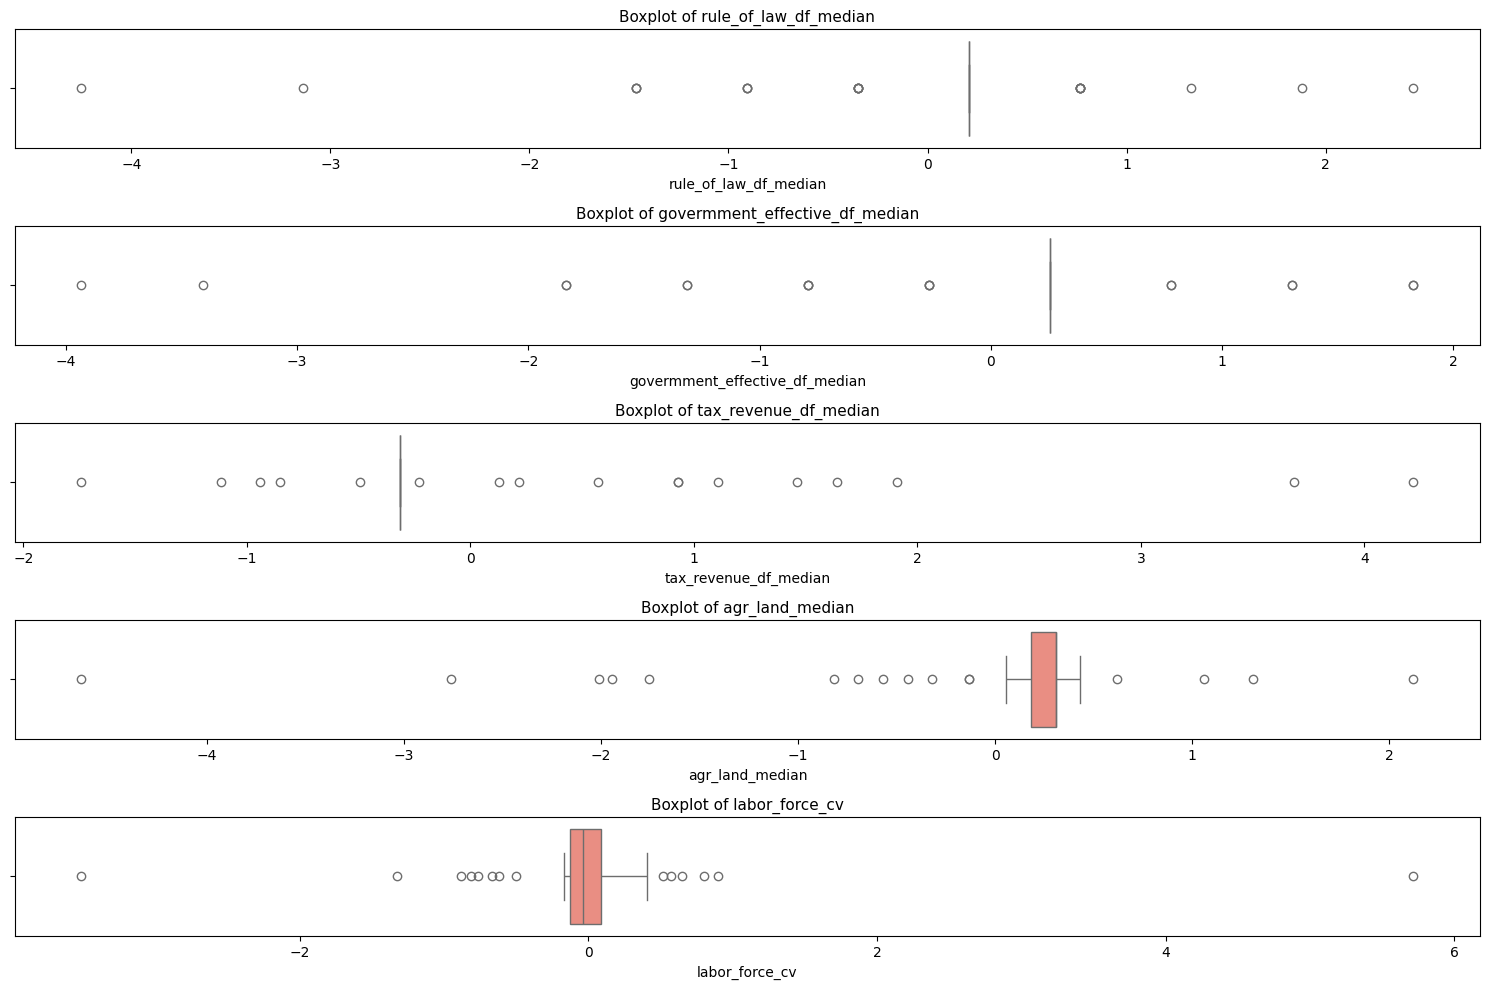

In [51]:
detect_top_outliers(master_df_without_zero_log_scaler)

In [52]:
def winsorize_outlier_columns(df, limits=(0.05, 0.05)):
    """
    Applies winsorization only to numeric columns that contain outliers (based on IQR).

    Parameters:
    - df: pandas DataFrame
    - limits: tuple (lower_limit, upper_limit) for winsorization percentiles

    Returns:
    - df_winsorized: DataFrame with selected columns winsorized
    - outlier_columns: list of columns that were winsorized
    """
    df_winsorized = df.copy()
    numeric_cols = df.select_dtypes(include='number').columns
    outlier_columns = []

    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]

        if not outliers.empty:
            arr = df[col].values
            arr_winsorized = winsorize(arr, limits=limits).data  # Convert to regular array
            df_winsorized[col] = arr_winsorized
            outlier_columns.append(col)

    return df_winsorized, outlier_columns

In [56]:
master_df_without_zero_log_scaler_win1, lists = winsorize_outlier_columns(master_df_without_zero_log_scaler)

Number of outliers per column (sorted):

rule_of_law_df_median: 21
govermment_effective_df_median: 18
tax_revenue_df_median: 17
agr_land_median: 16
labor_force_cv: 14
urban_pop_kurtosis: 14
reserves_trend: 13
unemployment_cv: 13
inflation_df_median: 13
edu_spending_df_median: 13
priv_cred_cv: 12
priv_cred_last: 12
labor_force_trend: 11
agr_land_trend: 11
priv_cred_min: 11
priv_cred_trend: 11
share_of_industry_df_median: 11
labor_force_min: 10
livestock_prod_cv: 10
gov_exp_last: 10
investment_min: 10
investment_last: 10
investment_trend: 10
priv_cred_mean: 10
rule_of_law_df_cv: 10
urban_pop_cv: 9
gdp_min: 9
priv_cred_median: 9
priv_cred_max: 9
share_of_industry_df_cv: 9
gov_exp_trend: 8
livestock_prod_median: 8
agr_land_cv: 8
reserves_median: 8
reserves_min: 8
reserves_last: 8
edu_spending_df_cv: 8
labor_force_std: 7
labor_force_mean: 7
labor_force_median: 6
agr_land_max: 6
urban_pop_skew: 6
reserves_mean: 6
unemployment_max: 6
tax_revenue_df_cv: 6
inflation_df_cv: 6
govermment_effectiv

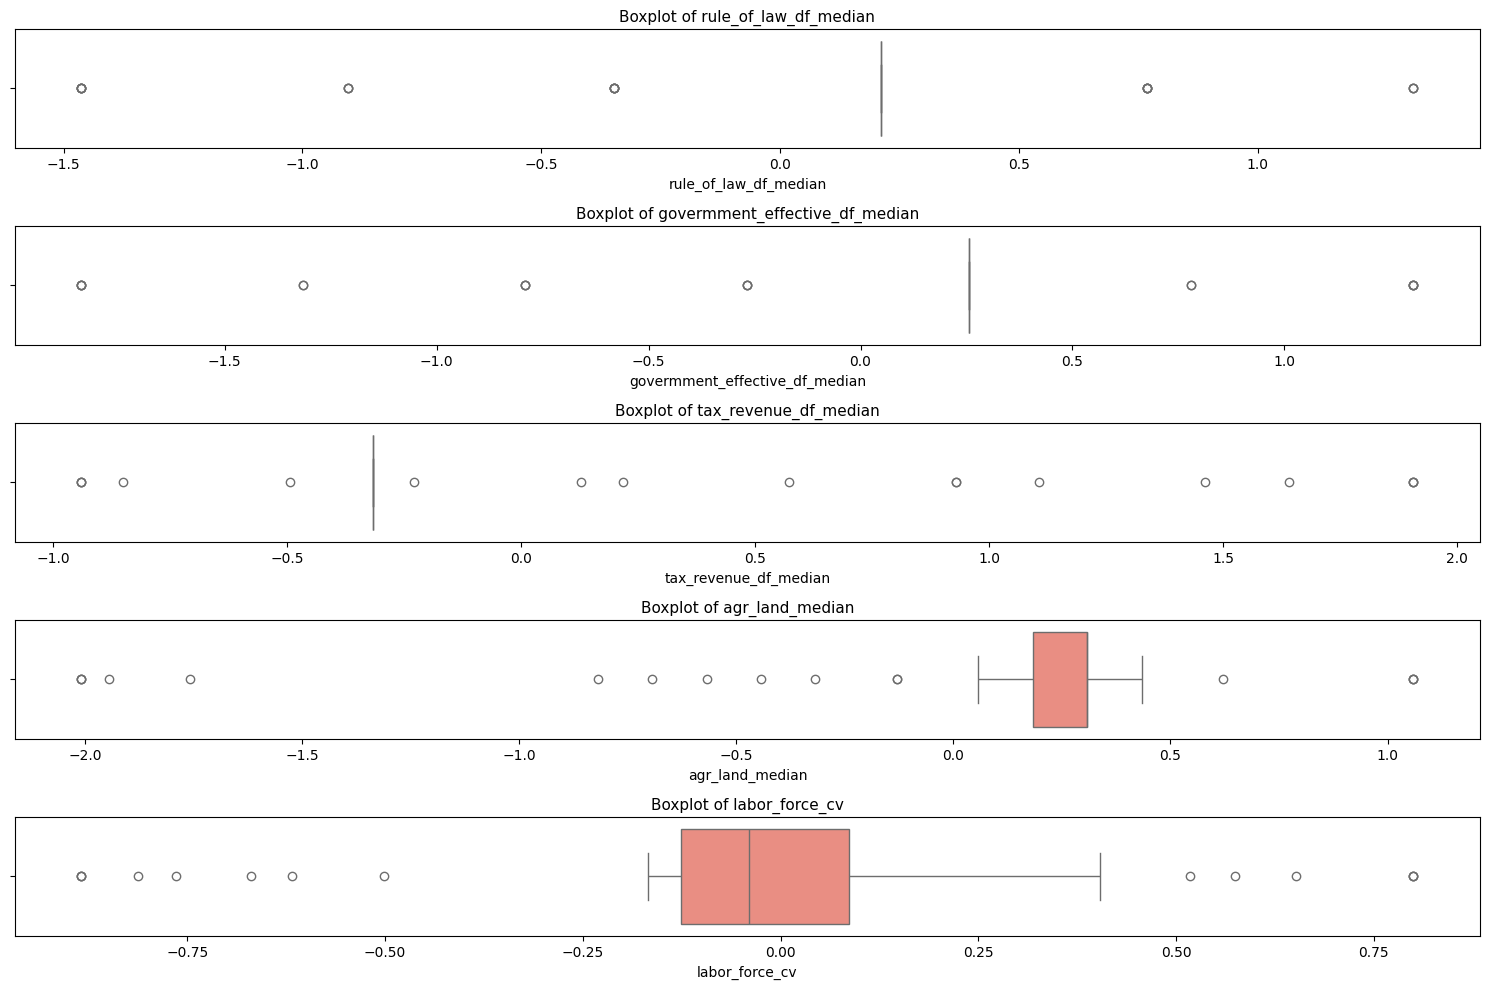

In [57]:
detect_top_outliers(master_df_without_zero_log_scaler_win1)

In [58]:
master_df_without_zero_log_scaler_win2, lists = winsorize_outlier_columns(master_df_without_zero_log_scaler_win1, limits=(0.08, 0.08))

Number of outliers per column (sorted):

rule_of_law_df_median: 21
govermment_effective_df_median: 18
tax_revenue_df_median: 17
labor_force_cv: 14
urban_pop_kurtosis: 14
reserves_trend: 13
unemployment_cv: 13
agr_land_median: 12
priv_cred_cv: 12
priv_cred_last: 12
priv_cred_min: 11
priv_cred_trend: 11
labor_force_min: 10
gov_exp_last: 10
investment_min: 10
investment_last: 10
investment_trend: 10
priv_cred_mean: 10
rule_of_law_df_cv: 10
inflation_df_median: 10
urban_pop_cv: 9
gdp_min: 9
priv_cred_median: 9
priv_cred_max: 9
edu_spending_df_median: 9
gov_exp_trend: 8
livestock_prod_median: 8
reserves_median: 8
reserves_min: 8
reserves_last: 8
labor_force_std: 7
labor_force_mean: 7
labor_force_trend: 7
livestock_prod_cv: 7
agr_land_trend: 7
share_of_industry_df_median: 7
labor_force_median: 6
agr_land_max: 6
urban_pop_skew: 6
reserves_mean: 6
unemployment_max: 6
investment_cv: 5
agr_land_std: 5
agr_land_cv: 5
gov_exp_kurtosis: 5
reserves_cv: 5
cpi_min: 5
cpi_skew: 5
share_of_industry_df_c

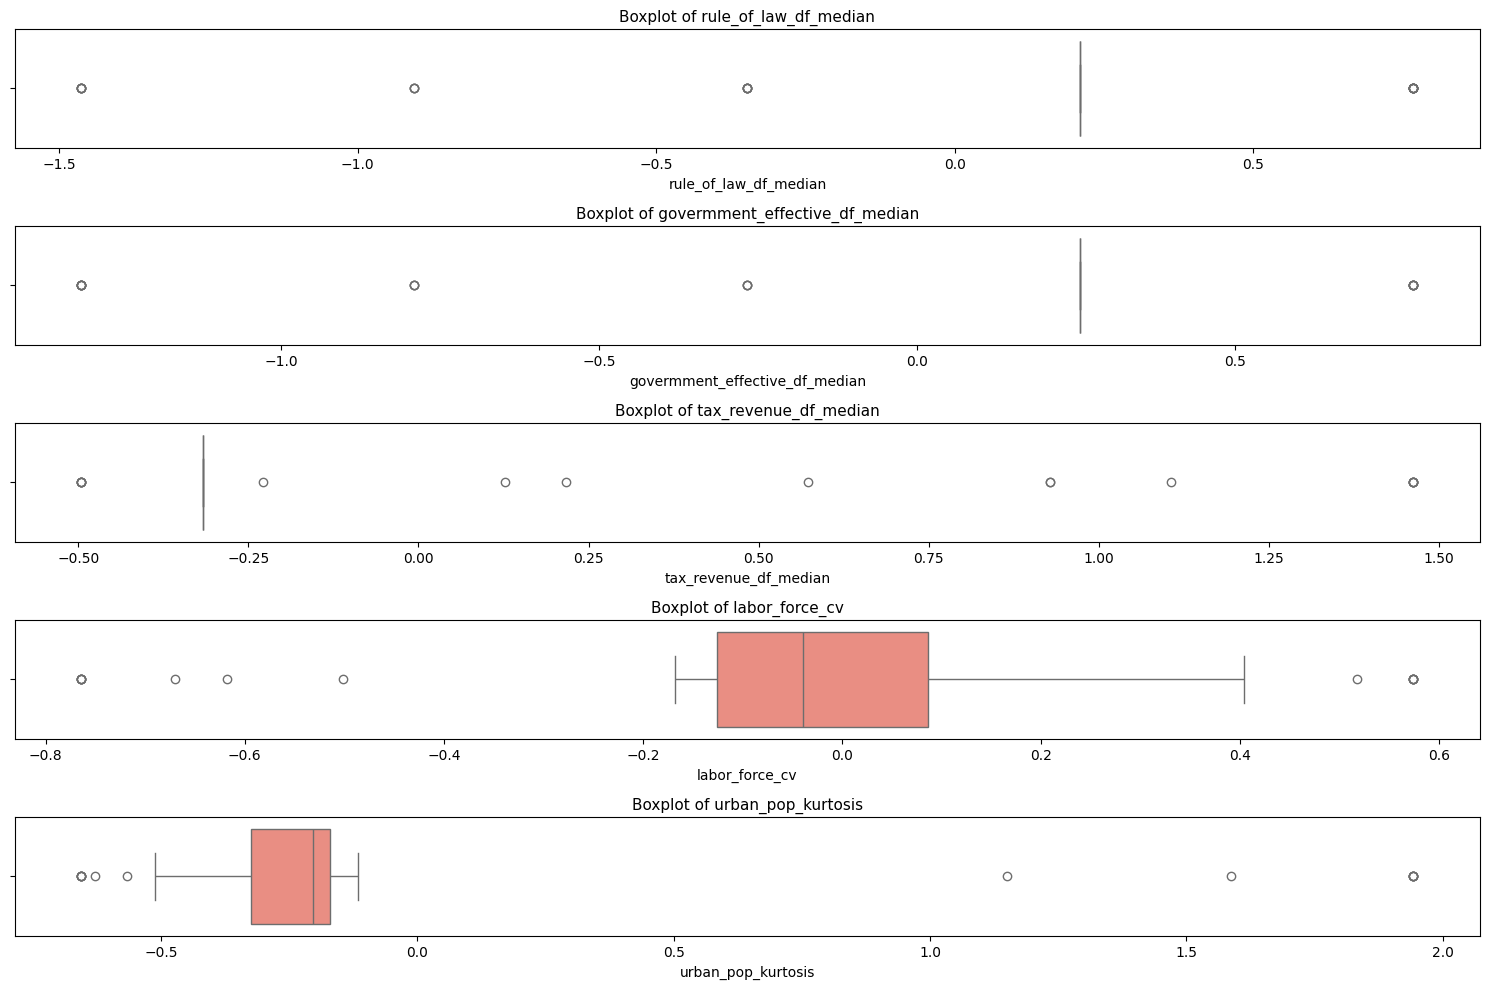

In [60]:
detect_top_outliers(master_df_without_zero_log_scaler_win2)

In [61]:
master_df_without_zero_log_scaler_win3, lists = winsorize_outlier_columns(master_df_without_zero_log_scaler_win2, limits=(0.10, 0.10))

Number of outliers per column (sorted):

rule_of_law_df_median: 21
govermment_effective_df_median: 18
labor_force_cv: 14
urban_pop_kurtosis: 14
agr_land_median: 12
priv_cred_last: 12
tax_revenue_df_median: 12
priv_cred_min: 11
priv_cred_trend: 11
labor_force_min: 10
gov_exp_last: 10
investment_min: 10
investment_last: 10
investment_trend: 10
priv_cred_mean: 10
inflation_df_median: 10
urban_pop_cv: 9
gdp_min: 9
priv_cred_median: 9
priv_cred_max: 9
edu_spending_df_median: 9
gov_exp_trend: 8
livestock_prod_median: 8
reserves_median: 8
reserves_min: 8
reserves_last: 8
reserves_trend: 8
unemployment_cv: 8
labor_force_std: 7
labor_force_mean: 7
labor_force_trend: 7
livestock_prod_cv: 7
agr_land_trend: 7
priv_cred_cv: 7
share_of_industry_df_median: 7
labor_force_median: 6
agr_land_max: 6
urban_pop_skew: 6
reserves_mean: 6
unemployment_max: 6
labor_force_max: 0
livestock_prod_std: 0
gov_exp_mean: 0
gov_exp_median: 0
gov_exp_std: 0
gov_exp_cv: 0
gov_exp_max: 0
reserves_std: 0
reserves_max: 0
in

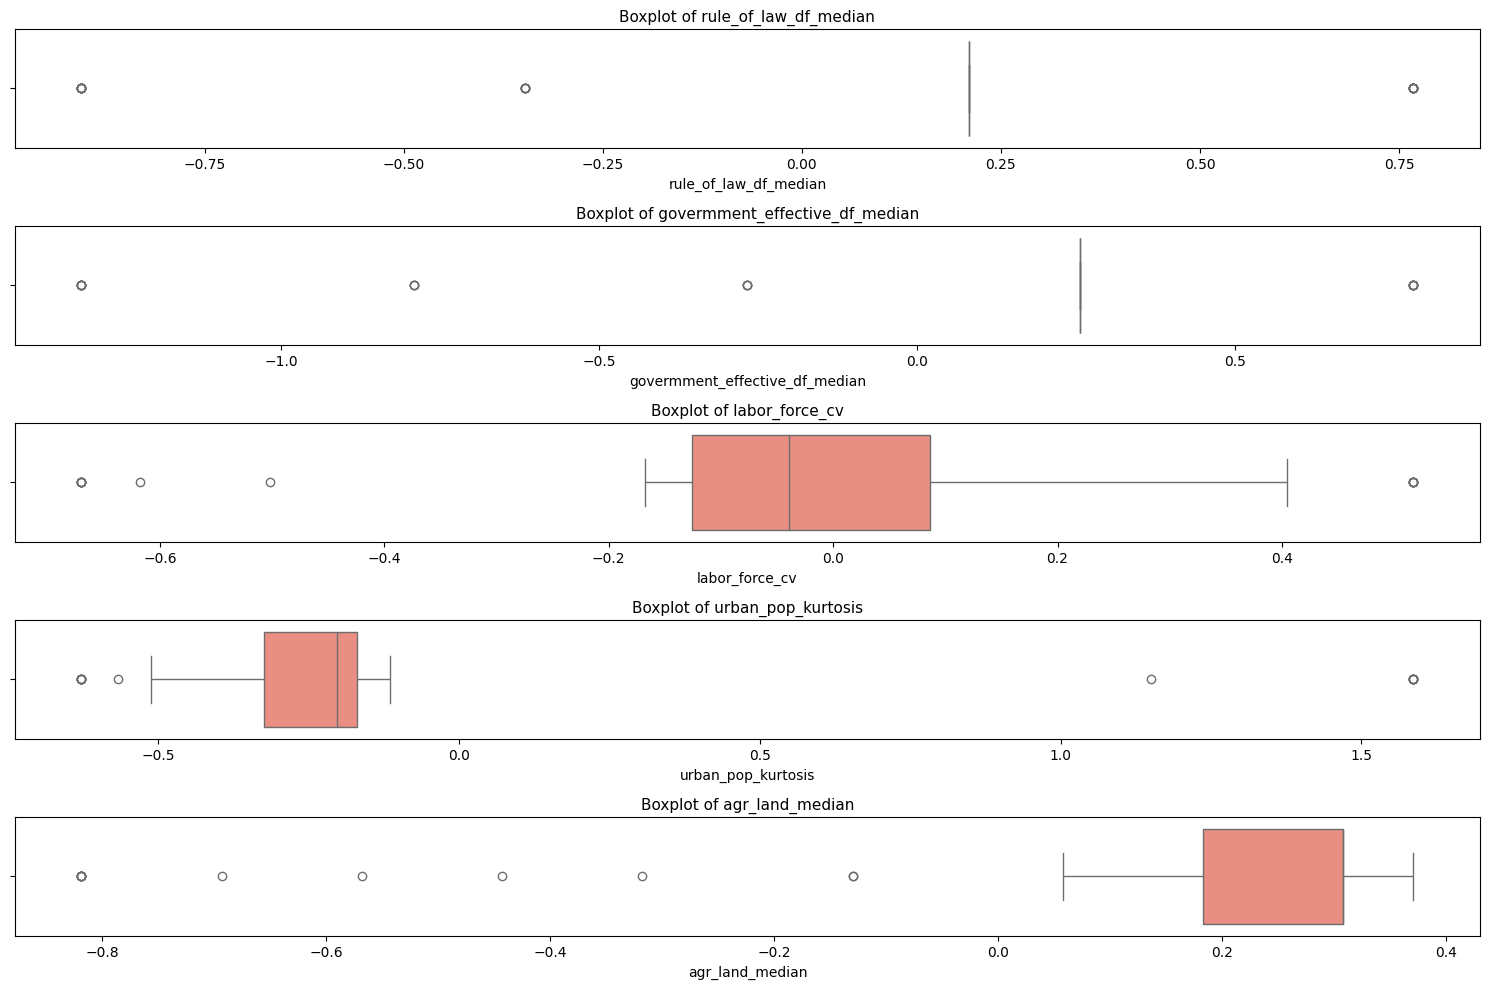

In [62]:
detect_top_outliers(master_df_without_zero_log_scaler_win3)

In [63]:
master_df_without_zero_log_scaler_win4, lists = winsorize_outlier_columns(master_df_without_zero_log_scaler_win3, limits=(0.12, 0.12))

Number of outliers per column (sorted):

rule_of_law_df_median: 21
urban_pop_kurtosis: 14
agr_land_median: 12
priv_cred_last: 12
tax_revenue_df_median: 12
govermment_effective_df_median: 12
priv_cred_min: 11
priv_cred_trend: 11
labor_force_min: 10
gov_exp_last: 10
investment_min: 10
investment_last: 10
investment_trend: 10
priv_cred_mean: 10
inflation_df_median: 10
urban_pop_cv: 9
gdp_min: 9
priv_cred_median: 9
priv_cred_max: 9
edu_spending_df_median: 9
gov_exp_trend: 8
labor_force_cv: 8
livestock_prod_median: 8
reserves_median: 8
reserves_min: 8
reserves_last: 8
reserves_trend: 8
unemployment_cv: 8
labor_force_std: 7
labor_force_mean: 7
labor_force_trend: 7
livestock_prod_cv: 7
agr_land_trend: 7
priv_cred_cv: 7
share_of_industry_df_median: 7
labor_force_max: 0
livestock_prod_std: 0
gov_exp_mean: 0
gov_exp_median: 0
gov_exp_std: 0
gov_exp_cv: 0
gov_exp_max: 0
reserves_std: 0
reserves_max: 0
investment_mean: 0
investment_median: 0
investment_std: 0
investment_cv: 0
investment_max: 0
cpi

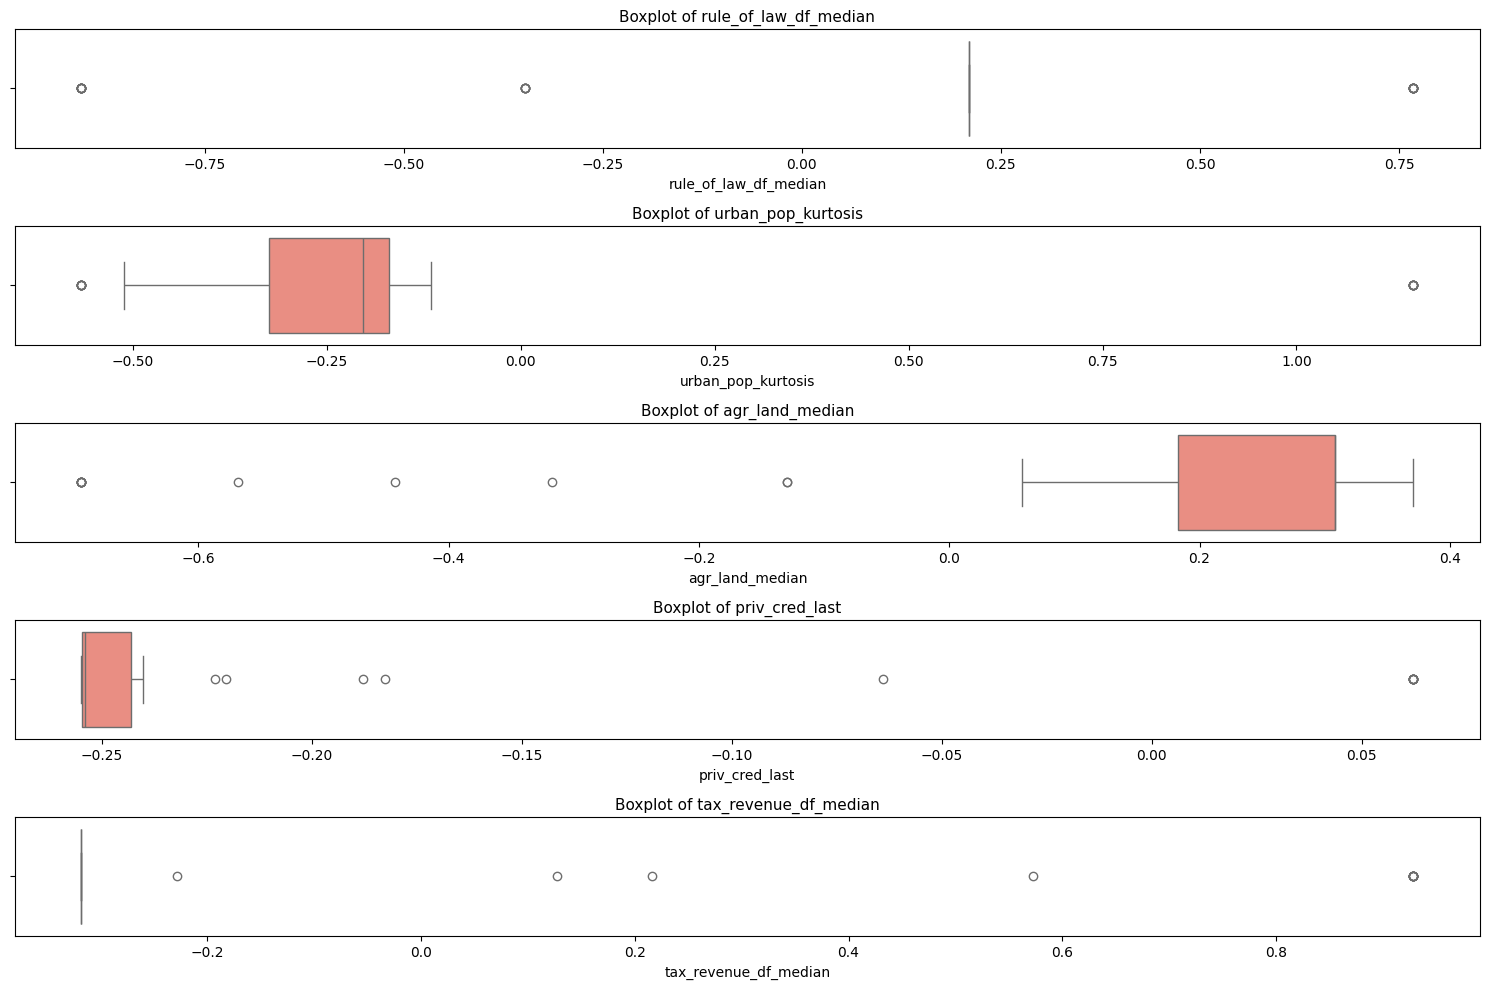

In [65]:
detect_top_outliers(master_df_without_zero_log_scaler_win4)

In [66]:
master_df_without_zero_log_scaler_win5, lists = winsorize_outlier_columns(master_df_without_zero_log_scaler_win4, limits=(0.15, 0.15))

Number of outliers per column (sorted):

rule_of_law_df_median: 21
agr_land_median: 12
priv_cred_last: 12
tax_revenue_df_median: 12
govermment_effective_df_median: 12
priv_cred_min: 11
priv_cred_trend: 11
labor_force_min: 10
gov_exp_last: 10
investment_min: 10
investment_last: 10
investment_trend: 10
priv_cred_mean: 10
inflation_df_median: 10
urban_pop_cv: 9
gdp_min: 9
priv_cred_median: 9
priv_cred_max: 9
edu_spending_df_median: 9
gov_exp_trend: 8
labor_force_cv: 8
livestock_prod_median: 8
reserves_median: 8
reserves_min: 8
reserves_last: 8
reserves_trend: 8
unemployment_cv: 8
labor_force_std: 0
labor_force_max: 0
livestock_prod_std: 0
gov_exp_mean: 0
gov_exp_median: 0
gov_exp_std: 0
gov_exp_cv: 0
gov_exp_max: 0
reserves_std: 0
reserves_max: 0
investment_mean: 0
investment_median: 0
investment_std: 0
investment_cv: 0
investment_max: 0
cpi_median: 0
cpi_std: 0
cpi_max: 0
cpi_last: 0
gdp_mean: 0
gdp_median: 0
gdp_std: 0
gdp_cv: 0
gdp_max: 0
gdp_last: 0
gdp_trend: 0
priv_cred_std: 0
unemp

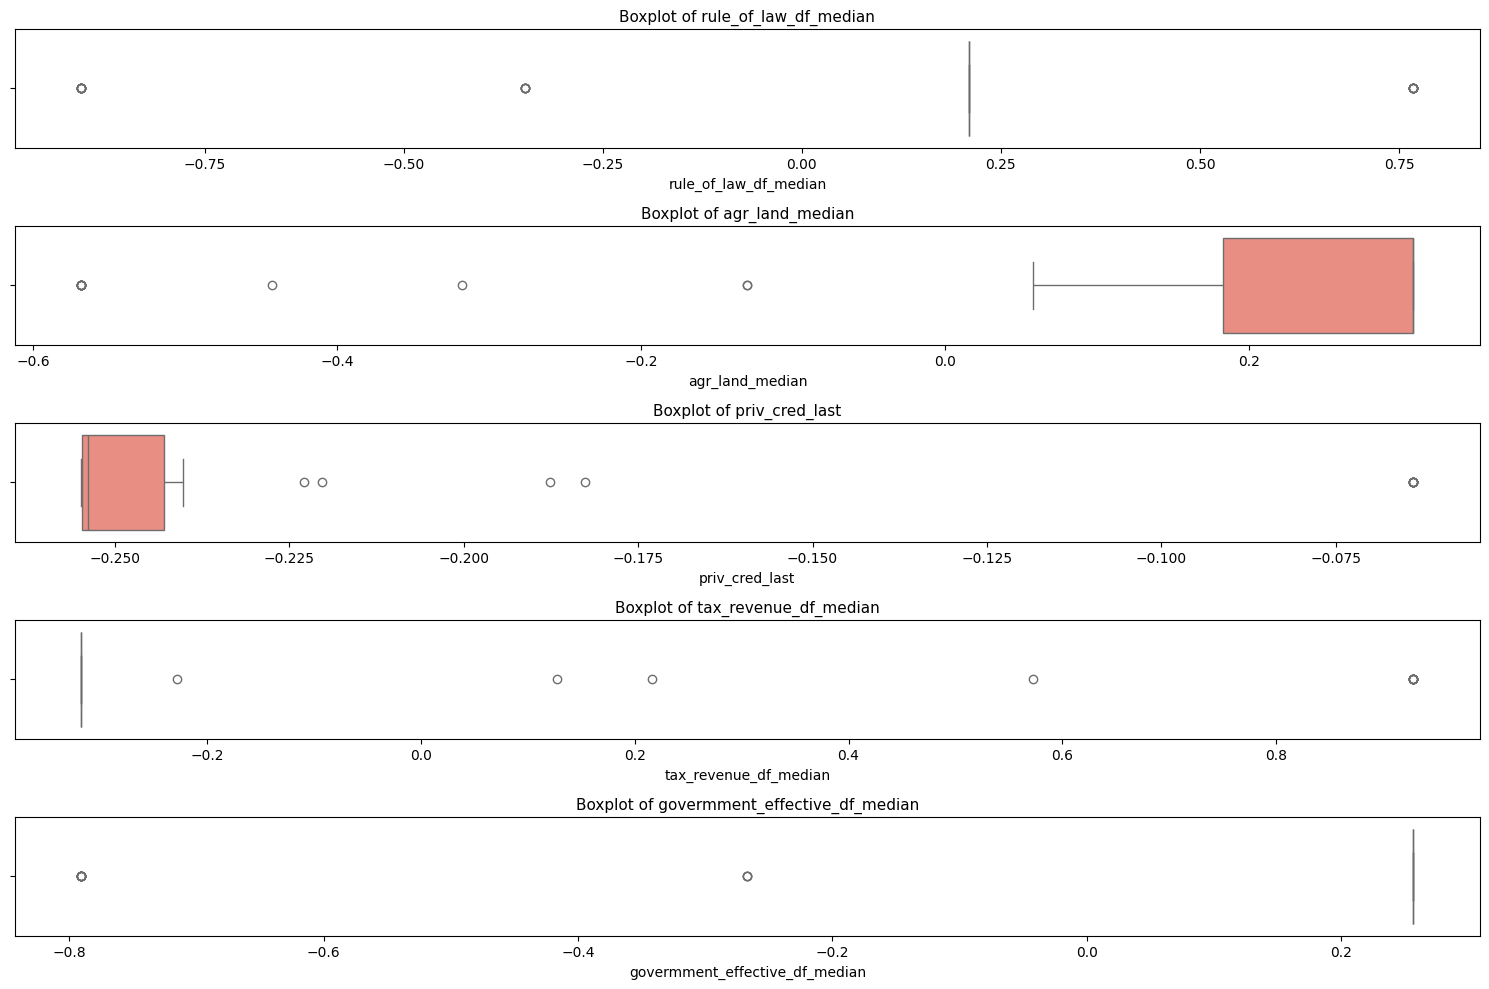

In [67]:
detect_top_outliers(master_df_without_zero_log_scaler_win5)

In [68]:
master_df_without_zero_log_scaler_win6, lists = winsorize_outlier_columns(master_df_without_zero_log_scaler_win5, limits=(0.18, 0.18))

Number of outliers per column (sorted):

rule_of_law_df_median: 13
agr_land_median: 12
priv_cred_last: 12
tax_revenue_df_median: 12
govermment_effective_df_median: 12
priv_cred_min: 11
priv_cred_trend: 11
labor_force_min: 10
gov_exp_last: 10
investment_min: 10
investment_last: 10
investment_trend: 10
priv_cred_mean: 10
inflation_df_median: 10
labor_force_std: 0
labor_force_max: 0
livestock_prod_std: 0
gov_exp_mean: 0
gov_exp_median: 0
gov_exp_std: 0
gov_exp_cv: 0
gov_exp_max: 0
gov_exp_trend: 0
reserves_std: 0
reserves_max: 0
investment_mean: 0
investment_median: 0
investment_std: 0
investment_cv: 0
investment_max: 0
cpi_median: 0
cpi_std: 0
cpi_max: 0
cpi_last: 0
gdp_mean: 0
gdp_median: 0
gdp_std: 0
gdp_cv: 0
gdp_max: 0
gdp_last: 0
gdp_trend: 0
priv_cred_std: 0
unemployment_std: 0
rule_of_law_df_std: 0
share_of_industry_df_std: 0
share_of_industry_df_max: 0
tax_revenue_df_std: 0
tax_revenue_df_max: 0
inflation_df_std: 0
inflation_df_max: 0
edu_spending_df_std: 0
govermment_effective_d

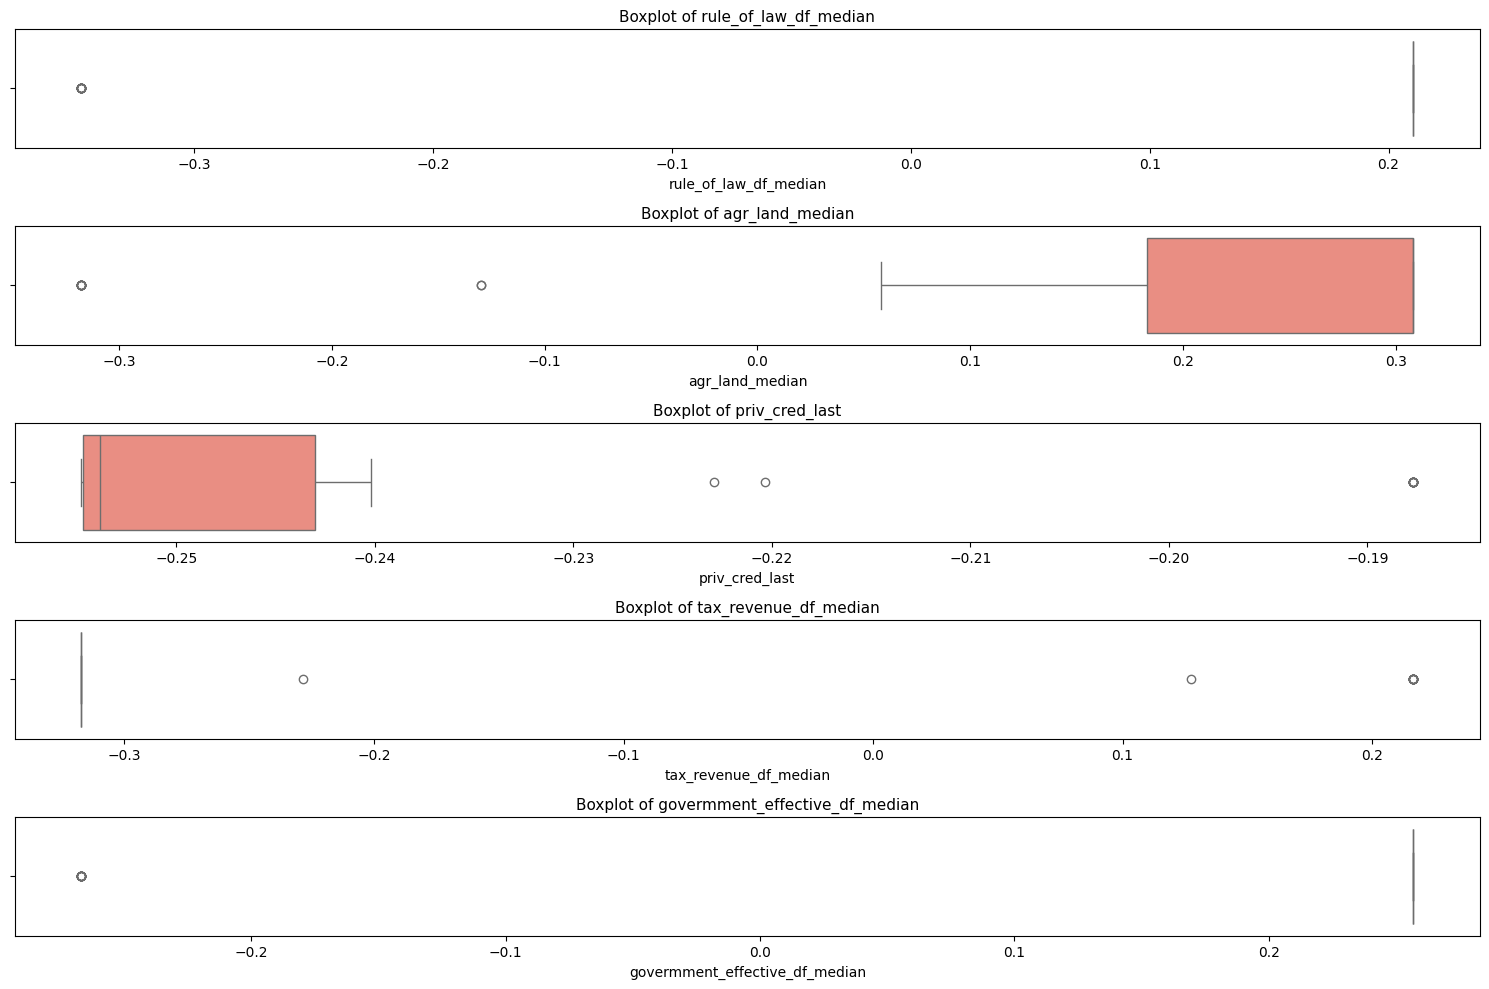

In [69]:
detect_top_outliers(master_df_without_zero_log_scaler_win6)

In [70]:
master_df_without_zero_log_scaler_win7, lists = winsorize_outlier_columns(master_df_without_zero_log_scaler_win6, limits=(0.19, 0.19))

Number of outliers per column (sorted):

rule_of_law_df_median: 13
agr_land_median: 12
priv_cred_last: 12
tax_revenue_df_median: 12
govermment_effective_df_median: 12
priv_cred_min: 11
priv_cred_trend: 11
labor_force_std: 0
labor_force_max: 0
livestock_prod_std: 0
gov_exp_mean: 0
gov_exp_median: 0
gov_exp_std: 0
gov_exp_cv: 0
gov_exp_max: 0
gov_exp_trend: 0
reserves_std: 0
reserves_max: 0
investment_mean: 0
investment_median: 0
investment_std: 0
investment_cv: 0
investment_max: 0
cpi_median: 0
cpi_std: 0
cpi_max: 0
cpi_last: 0
gdp_mean: 0
gdp_median: 0
gdp_std: 0
gdp_cv: 0
gdp_max: 0
gdp_last: 0
gdp_trend: 0
priv_cred_std: 0
unemployment_std: 0
rule_of_law_df_std: 0
share_of_industry_df_std: 0
share_of_industry_df_max: 0
tax_revenue_df_std: 0
tax_revenue_df_max: 0
inflation_df_std: 0
inflation_df_max: 0
edu_spending_df_std: 0
govermment_effective_df_std: 0
labor_force_mean: 0
labor_force_median: 0
labor_force_cv: 0
labor_force_min: 0
labor_force_skew: 0
labor_force_kurtosis: 0
labor_fo

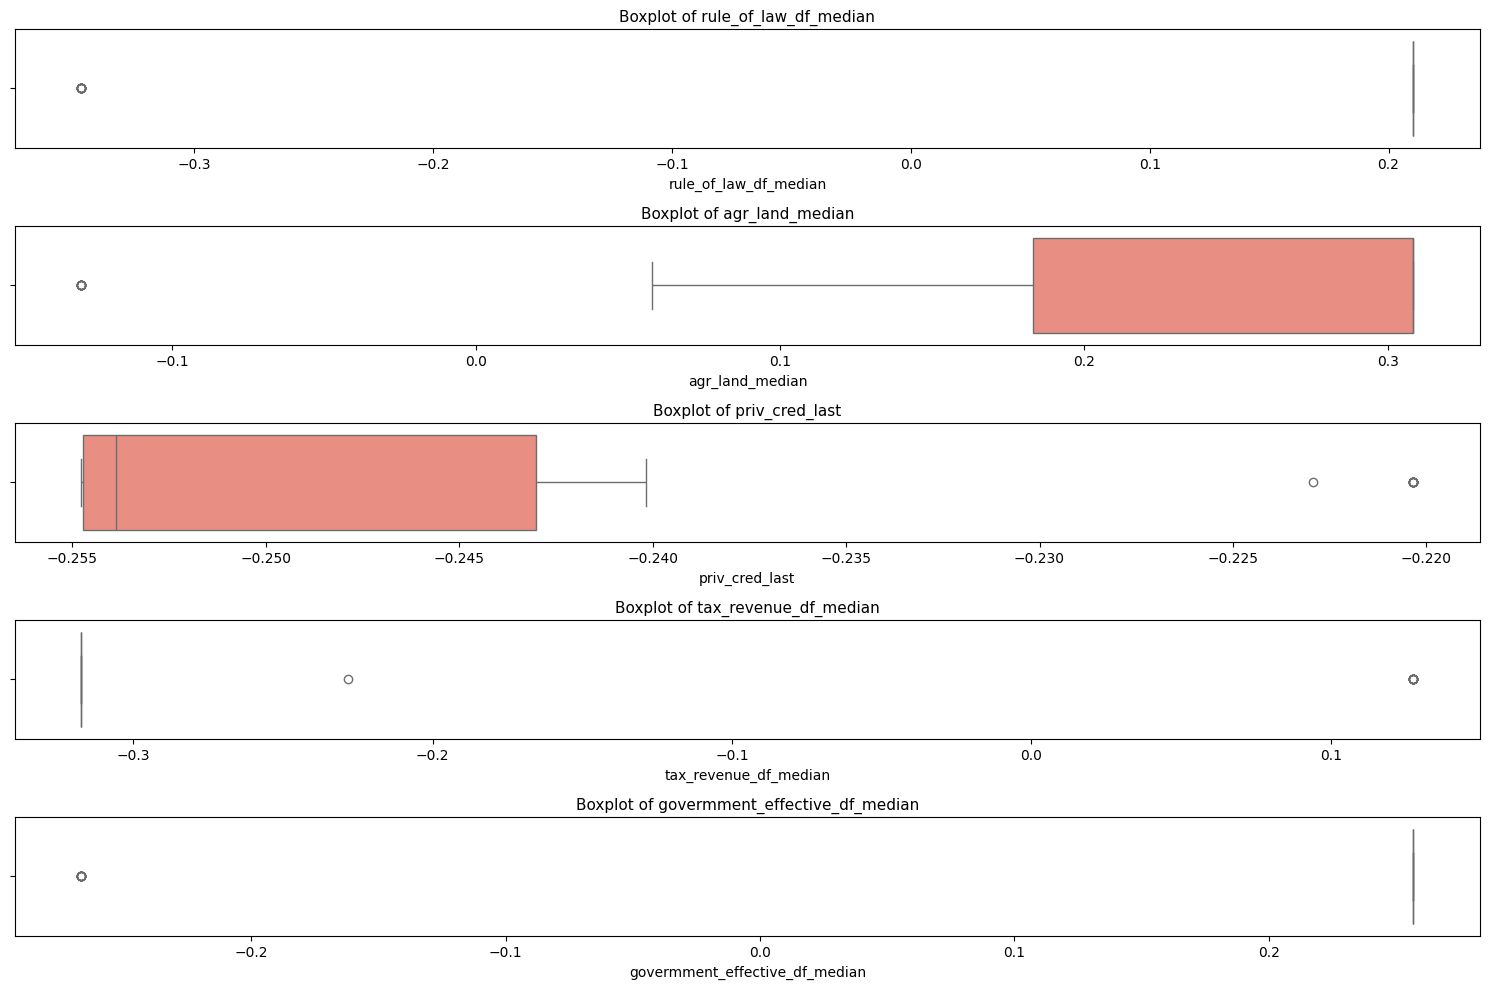

In [71]:
detect_top_outliers(master_df_without_zero_log_scaler_win7)

In [74]:
delete_columns = ["rule_of_law_df_median", 
                  "agr_land_median", 
                  "priv_cred_last", 
                  "tax_revenue_df_median", 
                  "govermment_effective_df_median", 
                  "priv_cred_min", 
                  "priv_cred_trend"]

In [75]:
def eliminar_columnas(df, columnas_a_borrar):
    """
    Elimina del DataFrame las columnas especificadas en la lista.

    Parámetros:
    - df: DataFrame original.
    - columnas_a_borrar: lista de nombres de columnas a eliminar.

    Retorna:
    - DataFrame sin las columnas indicadas.
    """
    columnas_existentes = [col for col in columnas_a_borrar if col in df.columns]
    return df.drop(columns=columnas_existentes).copy()

In [76]:
master_df_without_zero_log_scaler_win7_deleted_7 = eliminar_columnas(master_df_without_zero_log_scaler_win7, delete_columns)

Number of outliers per column (sorted):

labor_force_std: 0
labor_force_max: 0
livestock_prod_std: 0
gov_exp_mean: 0
gov_exp_median: 0
gov_exp_std: 0
gov_exp_cv: 0
gov_exp_max: 0
gov_exp_trend: 0
reserves_std: 0
reserves_max: 0
investment_mean: 0
investment_median: 0
investment_std: 0
investment_cv: 0
investment_max: 0
cpi_median: 0
cpi_std: 0
cpi_max: 0
cpi_last: 0
gdp_mean: 0
gdp_median: 0
gdp_std: 0
gdp_cv: 0
gdp_max: 0
gdp_last: 0
gdp_trend: 0
priv_cred_std: 0
unemployment_std: 0
rule_of_law_df_std: 0
share_of_industry_df_std: 0
share_of_industry_df_max: 0
tax_revenue_df_std: 0
tax_revenue_df_max: 0
inflation_df_std: 0
inflation_df_max: 0
edu_spending_df_std: 0
govermment_effective_df_std: 0
labor_force_mean: 0
labor_force_median: 0
labor_force_cv: 0
labor_force_min: 0
labor_force_skew: 0
labor_force_kurtosis: 0
labor_force_trend: 0
livestock_prod_mean: 0
livestock_prod_median: 0
livestock_prod_cv: 0
livestock_prod_min: 0
livestock_prod_max: 0
livestock_prod_skew: 0
livestock_prod_

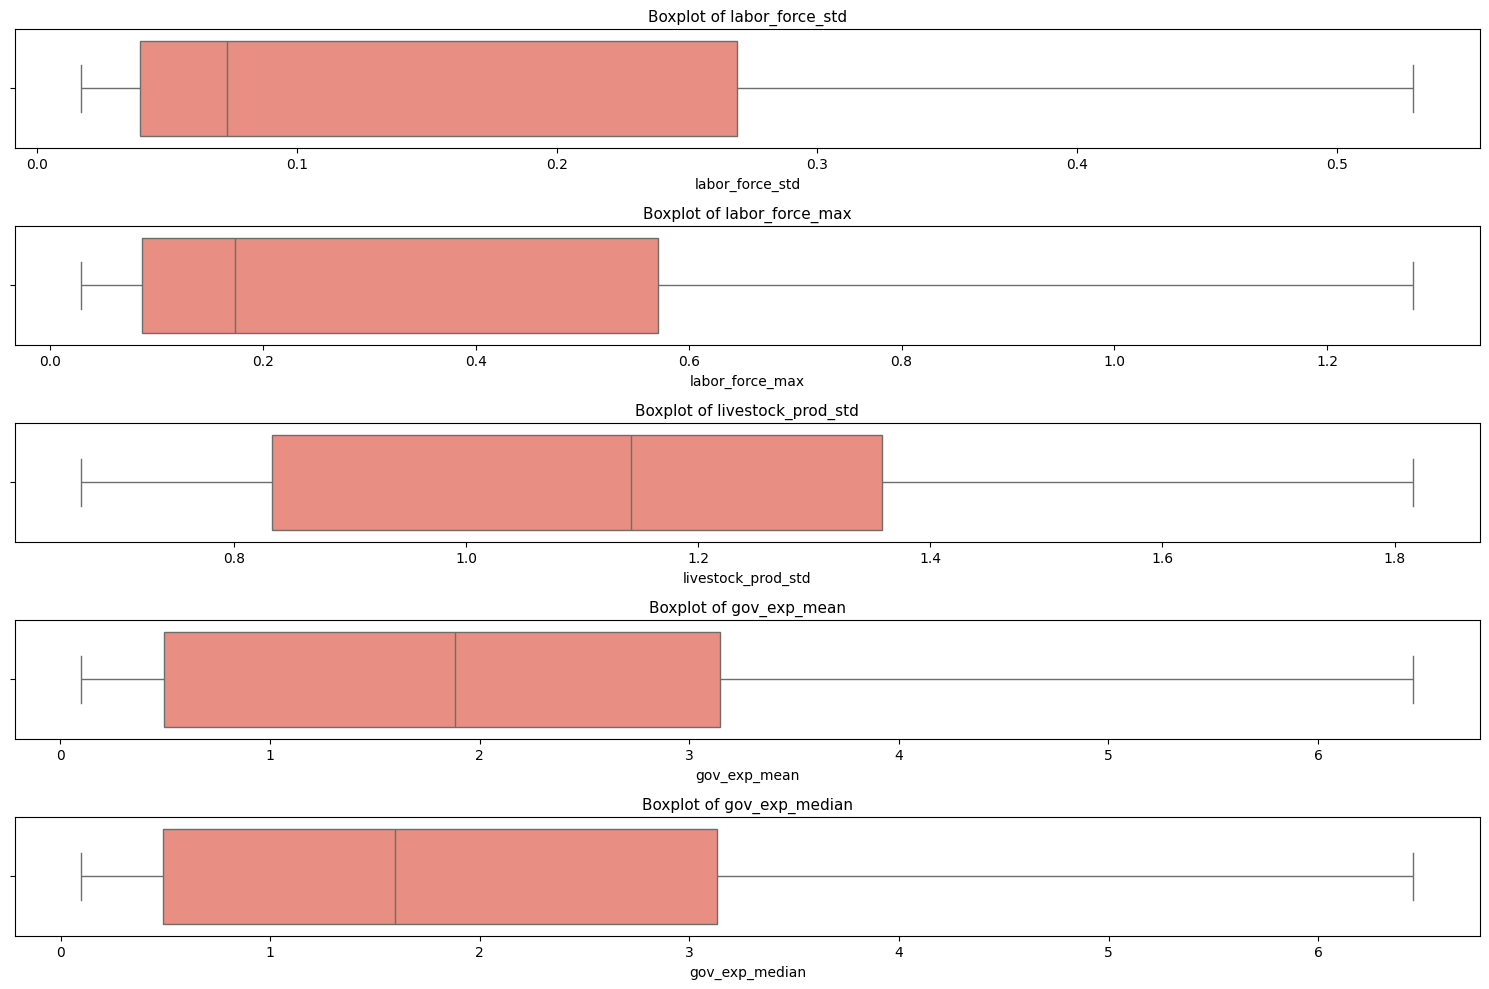

In [77]:
detect_top_outliers(master_df_without_zero_log_scaler_win7_deleted_7)

In [78]:
master_df_without_zero_log_scaler_win7_deleted_7.to_parquet('../data/diff_then_one_point_countries_then_delete_zeros_then_win7_then_delete_7features.parquet')

In [82]:
hpi_df = pd.read_parquet("../data/clean_hpi.parquet")

In [81]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

<Figure size 1400x600 with 0 Axes>

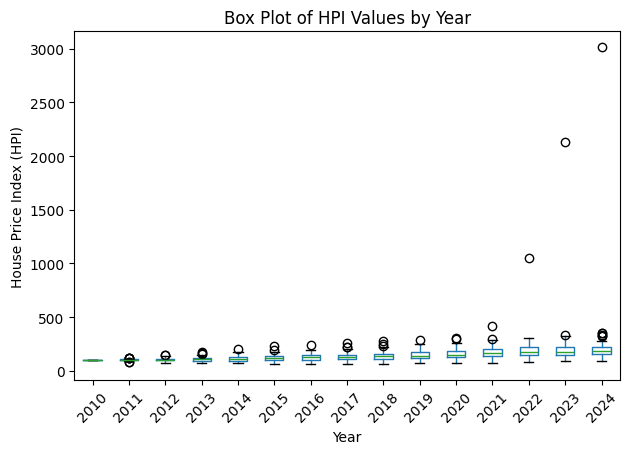

In [83]:
plot_hpi_boxplots_by_year(hpi_df)

In [84]:
hpi_df.head()

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,...,Slovenia,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom
0,2010,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,99.9975,100.0025,100.0000,...,99.9975,100.0000,99.9975,100.0025,100.0025,100.0000,100.0000,100.0000,100.00,100.0000
1,2011,97.8450,104.2250,103.5825,119.0225,94.4900,105.7500,112.2300,104.1175,107.8900,...,102.7150,103.5900,105.2275,92.3550,102.5800,107.5100,104.2625,108.8000,97.24,98.5450
2,2012,97.5325,117.1325,106.0150,133.0600,92.6900,110.6150,124.0250,103.4225,118.7925,...,95.6325,108.4075,108.2500,78.7075,103.8650,113.7225,107.6325,120.6750,101.82,98.9200
3,2013,103.9925,122.5900,107.5900,145.3175,90.6500,112.7600,136.5175,109.5550,130.0650,...,90.6200,115.4075,107.8000,71.5250,109.2225,118.3000,115.9925,134.4625,111.83,101.4550
4,2014,113.4075,126.7900,107.2250,155.3575,91.9475,118.8625,154.7200,112.3775,140.7525,...,84.6400,123.9875,109.4325,71.7450,119.5200,121.4650,127.0725,151.2500,118.88,109.6025


In [85]:
def detectar_outliers_por_año(df, metodo="iqr", umbral=1.5):
    """
    Detecta países que son outliers por año en un DataFrame de formato:
    - Columnas: países (numéricas)
    - Fila: años

    Parámetros:
    - df: DataFrame con columna 'Year' y columnas de países.
    - metodo: "iqr" (interquartile range) o "zscore"
    - umbral: sensibilidad del método (1.5 para IQR, 3 para z-score)

    Retorna:
    - Diccionario con años como claves y lista de países outliers como valores.
    """
    outliers_por_año = {}

    paises = [col for col in df.columns if col != "Year"]

    for idx, row in df.iterrows():
        año = row["Year"]
        valores = row[paises].dropna()

        if metodo == "iqr":
            q1 = valores.quantile(0.25)
            q3 = valores.quantile(0.75)
            iqr = q3 - q1
            lower_bound = q1 - umbral * iqr
            upper_bound = q3 + umbral * iqr
            outliers = valores[(valores < lower_bound) | (valores > upper_bound)]
        elif metodo == "zscore":
            mean = valores.mean()
            std = valores.std()
            outliers = valores[(abs(valores - mean) > umbral * std)]
        else:
            raise ValueError("Método no válido. Usa 'iqr' o 'zscore'.")

        outliers_por_año[año] = list(outliers.index)

    return outliers_por_año

In [86]:
countries_outliers = detectar_outliers_por_año(hpi_df)

In [87]:
countries_outliers

{np.float64(2010.0): [],
 np.float64(2011.0): ['Brazil',
  'Hong-Kong',
  'India',
  'Ireland',
  'Peru',
  'Russia'],
 np.float64(2012.0): ['India', 'Peru'],
 np.float64(2013.0): ['Hong-Kong', 'India', 'Peru'],
 np.float64(2014.0): ['India'],
 np.float64(2015.0): ['Hong-Kong', 'India'],
 np.float64(2016.0): ['India'],
 np.float64(2017.0): ['Hong-Kong', 'India', 'Turkey'],
 np.float64(2018.0): ['Hong-Kong', 'India', 'Turkey'],
 np.float64(2019.0): ['India'],
 np.float64(2020.0): ['India', 'Turkey'],
 np.float64(2021.0): ['India', 'Turkey'],
 np.float64(2022.0): ['Turkey'],
 np.float64(2023.0): ['Chile', 'Turkey'],
 np.float64(2024.0): ['Chile',
  'Estonia',
  'Hungary',
  'Iceland',
  'India',
  'Turkey']}

In [88]:
def detectar_outliers_con_alejamiento(df, metodo="iqr", umbral=1.5):
    """
    Detecta países outliers por año y calcula cuán alejados están del centro.

    Retorna:
    - Diccionario con años como claves.
    - Cada valor es una lista de tuplas: (país, valor, medida de alejamiento)
    """
    resultado = {}
    paises = [col for col in df.columns if col != "Year"]

    for idx, row in df.iterrows():
        año = row["Year"]
        valores = row[paises].dropna()

        outliers_info = []

        if metodo == "iqr":
            q1 = valores.quantile(0.25)
            q3 = valores.quantile(0.75)
            iqr = q3 - q1
            lower = q1 - umbral * iqr
            upper = q3 + umbral * iqr

            for pais, valor in valores.items():
                if valor < lower or valor > upper:
                    distancia = max(valor - upper, lower - valor)
                    outliers_info.append((pais, valor, round(distancia, 2)))

        elif metodo == "zscore":
            mean = valores.mean()
            std = valores.std()
            for pais, valor in valores.items():
                z = (valor - mean) / std if std != 0 else 0
                if abs(z) > umbral:
                    outliers_info.append((pais, valor, round(z, 2)))

        resultado[año] = outliers_info

    return resultado

In [89]:
outliers_distance = detectar_outliers_con_alejamiento(hpi_df)

In [92]:
for año, lista in outliers_distance.items():
    print(f"Año {año}:")
    for pais, valor, alejamiento in lista:
        print(f"  {pais}: valor={valor}, alejamiento={alejamiento}")

Año 2010.0:
Año 2011.0:
  Brazil: valor=119.0225, alejamiento=0.19
  Hong-Kong: valor=120.63499999999999, alejamiento=1.81
  India: valor=122.2475, alejamiento=3.42
  Ireland: valor=82.9275, alejamiento=3.3
  Peru: valor=120.4325, alejamiento=1.6
  Russia: valor=79.19, alejamiento=7.04
Año 2012.0:
  India: valor=151.8775, alejamiento=12.47
  Peru: valor=143.1275, alejamiento=3.72
Año 2013.0:
  Hong-Kong: valor=160.60000000000002, alejamiento=2.14
  India: valor=173.92, alejamiento=15.46
  Peru: valor=162.8475, alejamiento=4.38
Año 2014.0:
  India: valor=199.65, alejamiento=25.62
Año 2015.0:
  Hong-Kong: valor=196.6575, alejamiento=5.92
  India: valor=226.7925, alejamiento=36.05
Año 2016.0:
  India: valor=241.95499999999998, alejamiento=28.24
Año 2017.0:
  Hong-Kong: valor=221.255, alejamiento=10.52
  India: valor=262.3075, alejamiento=51.57
  Turkey: valor=218.8125, alejamiento=8.08
Año 2018.0:
  Hong-Kong: valor=250.0475, alejamiento=24.31
  India: valor=277.255, alejamiento=51.52
  T

In [93]:
delete_countries = ["Hong-Kong","India","Turkey"]

In [94]:
def eliminar_columnas_por_lista(df, lista_paises):
    """
    Elimina del DataFrame las columnas cuyos nombres están en la lista de países.

    Parámetros:
    - df: DataFrame original.
    - lista_paises: lista de nombres de columnas a eliminar.

    Retorna:
    - DataFrame sin las columnas indicadas.
    """
    columnas_a_eliminar = [col for col in lista_paises if col in df.columns]
    return df.drop(columns=columnas_a_eliminar).copy()

In [95]:
hpi_without_3_countries = eliminar_columnas_por_lista(hpi_df, delete_countries)

<Figure size 1400x600 with 0 Axes>

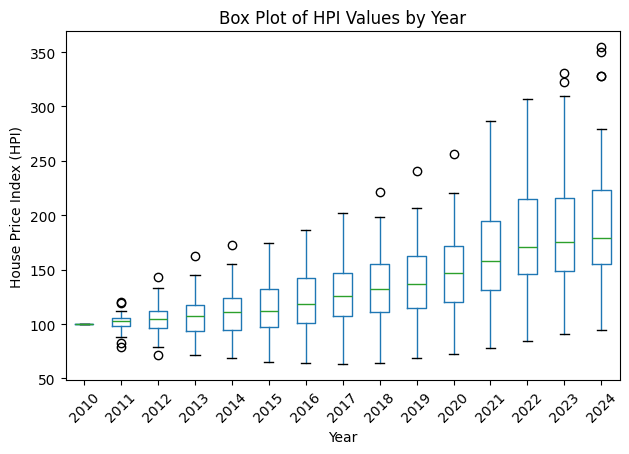

In [96]:
plot_hpi_boxplots_by_year(hpi_without_3_countries)

In [99]:
def round_and_winsorize_hpi(df_hpi, year_column='Year', limits=(0.05, 0.05)):
    """
    Rounds all HPI values to two decimals, then applies Winsorization per year.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - limits: Tuple indicating proportion to cut from each tail (default: 10%)

    Returns:
    - DataFrame with rounded and Winsorized HPI values
    """

    # Step 1: Round all numeric values to 2 decimals
    df_rounded = df_hpi.copy()
    country_columns = [col for col in df_rounded.columns if col != year_column]
    df_rounded[country_columns] = df_rounded[country_columns].round(2)

    # Step 2: Apply Winsorization row by row
    df_winsorized = df_rounded.copy()

    for idx, row in df_rounded.iterrows():
        values = row[country_columns].values.astype(float)

        # Apply Winsorization only if enough valid values
        if np.count_nonzero(~np.isnan(values)) >= 4:
            winsorized = winsorize(values, limits=limits)
            df_winsorized.loc[idx, country_columns] = winsorized

    return df_winsorized

In [100]:
hpi_without_3_countries_win1 = round_and_winsorize_hpi(hpi_without_3_countries)

<Figure size 1400x600 with 0 Axes>

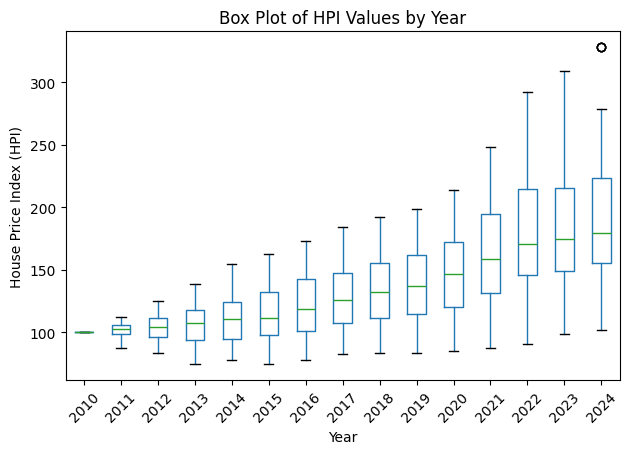

In [101]:
plot_hpi_boxplots_by_year(hpi_without_3_countries_win1)

In [102]:
hpi_without_3_countries_win2 = round_and_winsorize_hpi(hpi_without_3_countries_win1, limits=(0.065, 0.065))

<Figure size 1400x600 with 0 Axes>

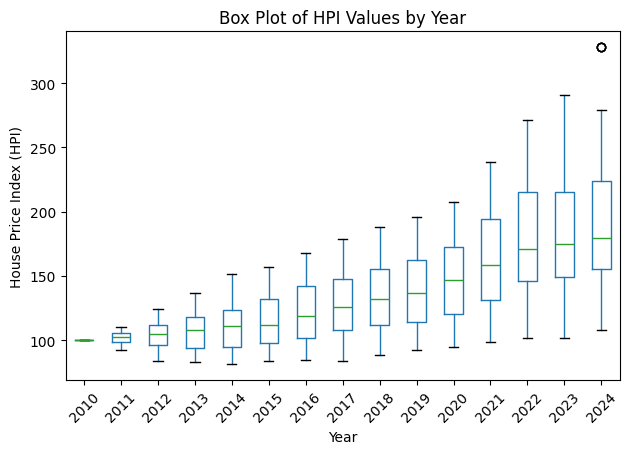

In [103]:
plot_hpi_boxplots_by_year(hpi_without_3_countries_win2)

In [104]:
hpi_without_3_countries_win3 = round_and_winsorize_hpi(hpi_without_3_countries_win2, limits=(0.07, 0.07))

<Figure size 1400x600 with 0 Axes>

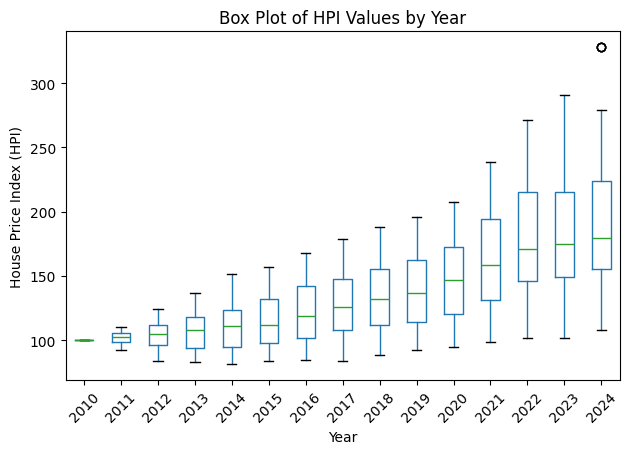

In [105]:
plot_hpi_boxplots_by_year(hpi_without_3_countries_win3)

In [108]:
hpi_without_3_countries_win4 = round_and_winsorize_hpi(hpi_without_3_countries_win3, limits=(0.08, 0.08))

<Figure size 1400x600 with 0 Axes>

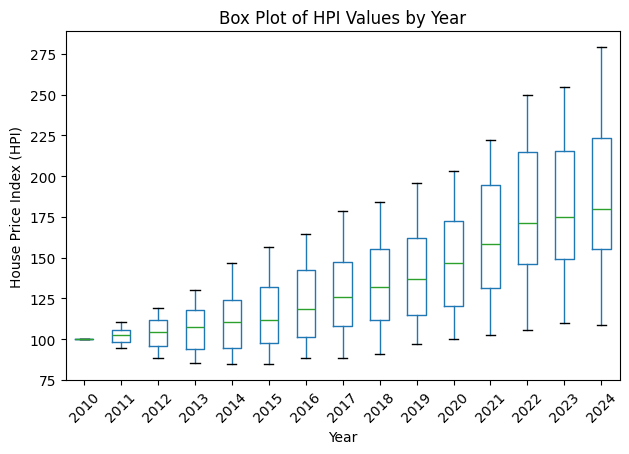

In [109]:
plot_hpi_boxplots_by_year(hpi_without_3_countries_win4)

In [110]:
hpi_without_3_countries_win4.to_parquet("../data/hpi_3_deleted_countries_winsorized4.parquet")

In [111]:
def eliminar_filas_por_paises(df, lista_paises, columna="Country"):
    """
    Elimina filas del DataFrame donde el valor en la columna 'country' está en la lista de países.

    Parámetros:
    - df: DataFrame original.
    - lista_paises: lista de nombres de países a eliminar.
    - columna: nombre de la columna que contiene los países (por defecto 'country').

    Retorna:
    - DataFrame sin las filas correspondientes a esos países.
    """
    return df[~df[columna].isin(lista_paises)].copy()

In [114]:
master_df_without_zero_deleted_3_countries = eliminar_filas_por_paises(master_df_without_zero, delete_countries)

In [113]:
master_df_without_zero_log_scaler_win7_deleted_7_deleted_3_countries = eliminar_filas_por_paises(master_df_without_zero_log_scaler_win7_deleted_7, delete_countries)

In [115]:
hpi_without_3_countries_win4.shape

(15, 55)

In [116]:
master_df_without_zero_deleted_3_countries.shape

(51, 160)

In [118]:
master_df_without_zero_log_scaler_win7_deleted_7_deleted_3_countries.shape

(51, 153)

In [119]:
hpi_without_3_countries_win4.head()

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,...,Slovakia,Slovenia,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,USA,United-Kingdom
0,2010,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,...,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
1,2011,97.84,104.22,103.58,110.42,94.49,105.75,110.42,104.12,107.89,...,98.46,102.72,103.59,105.23,94.49,102.58,107.51,104.26,97.24,98.54
2,2012,97.53,117.13,106.02,118.79,92.69,110.62,118.79,103.42,118.79,...,95.73,95.63,108.41,108.25,88.37,103.86,113.72,107.63,101.82,98.92
3,2013,103.99,122.59,107.59,130.06,90.65,112.76,130.06,109.56,130.06,...,96.53,90.62,115.41,107.80,85.58,109.22,118.30,115.99,111.83,101.46
4,2014,113.41,126.79,107.22,146.41,91.95,118.86,146.41,112.38,140.75,...,97.80,84.64,123.99,109.43,84.64,119.52,121.46,127.07,118.88,109.60


In [120]:
master_df_without_zero_deleted_3_countries.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_skew,labor_force_kurtosis,labor_force_trend,...,edu_spending_df_trend,govermment_effective_df_mean,govermment_effective_df_median,govermment_effective_df_std,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,Australia,0.177,0.245,0.154858,0.874904,-0.01,0.43,-0.055214,-1.470372,0.014727,...,-0.002970,0.006,0.00,0.047582,7.930252,-0.10,0.06,-0.714489,0.008940,0.002667
1,Austria,0.026,0.025,0.029732,1.143544,-0.02,0.07,0.139709,-1.244774,0.004121,...,-0.016061,-0.014,0.00,0.064529,-4.609219,-0.13,0.12,0.178013,0.092429,-0.008364
2,Belgium,0.042,0.050,0.042379,1.009030,-0.02,0.11,0.034370,-1.356918,0.003152,...,-0.003455,-0.036,-0.01,0.090465,-2.512930,-0.19,0.14,-0.036566,-0.315602,0.002061
3,Brazil,0.490,0.600,2.586797,5.279178,-6.21,4.11,-1.395227,1.933179,0.020121,...,-0.004364,-0.030,-0.01,0.137695,-4.589844,-0.24,0.29,0.712911,0.705002,0.000848
4,Bulgaria,-0.018,-0.015,0.057585,-3.199151,-0.12,0.09,0.129332,-0.434776,-0.010182,...,0.006667,-0.004,0.00,0.162247,-40.561681,-0.38,0.32,-0.457424,1.491768,0.008242


In [121]:
master_df_without_zero_log_scaler_win7_deleted_7_deleted_3_countries.head()

,Country,labor_force_std,labor_force_max,livestock_prod_std,gov_exp_mean,gov_exp_median,gov_exp_std,gov_exp_cv,gov_exp_max,gov_exp_trend,...,edu_spending_df_skew,edu_spending_df_kurtosis,edu_spending_df_trend,govermment_effective_df_mean,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,Australia,0.143977,0.357674,1.554548,2.136767,2.262414,1.507192,0.385463,2.615569,0.755168,...,0.493104,-1.488040,0.063886,0.567630,0.796482,0.570699,-1.003472,-0.783260,-0.276379,0.521790
1,Austria,0.029299,0.067659,0.668800,0.666803,0.546675,0.496587,0.517829,1.145019,0.177893,...,-1.199757,1.294932,-0.427952,-0.287040,-0.262984,0.232113,-0.145665,0.269123,-0.196556,-1.047159
2,Belgium,0.041506,0.104360,1.147336,0.805024,0.665262,0.630444,0.536660,1.345472,0.230306,...,0.667567,1.020573,0.045669,-1.227178,-0.085868,-0.445060,0.140270,0.016105,-0.586669,0.435584
3,Brazil,0.529323,1.280934,1.040778,3.281428,3.129935,2.842337,0.489039,4.064830,1.701274,...,-0.355222,-1.696472,0.011514,-0.970776,-0.261347,-1.009370,1.998852,0.899841,0.389117,0.263172
4,Bulgaria,0.055988,0.086178,1.198873,0.493476,0.488580,0.353456,0.509553,0.896088,0.131639,...,0.350505,0.039883,0.425933,0.140295,-0.564445,-1.009370,1.998852,-0.480145,1.141334,1.314885


In [122]:
def limpiar_nombres_paises(df):
    """
    Reemplaza los guiones '-' por espacios ' ' en la columna 'Country' de un DataFrame.
    """
    df = df.copy()
    if "Country" in df.columns:
        df["Country"] = df["Country"].astype(str).str.replace("-", " ")
    return df

In [123]:
def limpiar_nombres_columnas(df):
    """
    Reemplaza los guiones '-' por espacios ' ' en los nombres de las columnas del DataFrame.
    """
    df = df.copy()
    df.columns = [col.replace("-", " ") for col in df.columns]
    return df

In [124]:
master_df_without_zero_deleted_3_countries = limpiar_nombres_paises(master_df_without_zero_deleted_3_countries)

In [125]:
master_df_without_zero_log_scaler_win7_deleted_7_deleted_3_countries = limpiar_nombres_paises(master_df_without_zero_log_scaler_win7_deleted_7_deleted_3_countries)

In [126]:
hpi_without_3_countries_win4 = limpiar_nombres_columnas(hpi_without_3_countries_win4)

In [136]:
def comparar_paises_columnas_vs_filas(df_columnas, df_filas, columna_filas="Country"):
    """
    Compara los nombres de países entre:
    - Las columnas de df_columnas.
    - Los valores de la columna 'Country' en df_filas.

    Retorna:
    - Diccionario con:
        - 'faltan_en_filas': países que están como columnas pero no en la columna 'Country'.
        - 'faltan_en_columnas': países que están en la columna 'Country' pero no como columnas.
    """
    # Asegurarse de que los nombres estén limpios
    paises_columnas = set([col.strip() for col in df_columnas.columns if col != "Year"])
    paises_filas = set(df_filas[columna_filas].dropna().astype(str).str.strip())

    faltan_en_filas = sorted(paises_columnas - paises_filas)
    faltan_en_columnas = sorted(paises_filas - paises_columnas)

    return {
        "faltan_en_filas": faltan_en_filas,
        "faltan_en_columnas": faltan_en_columnas
    }

In [138]:
comparar_paises_columnas_vs_filas(hpi_without_3_countries_win4, master_df_without_zero_deleted_3_countries)

{'faltan_en_filas': ['China',
  'Czech Republic',
  'Indonesia',
  'Macedonia',
  'Morocco',
  'New Zealand',
  'South Africa',
  'South Korea',
  'United Kingdom'],
 'faltan_en_columnas': ['Czech', 'New', 'Paraguay', 'South', 'United']}

In [139]:
def reemplazar_nombres_paises(df):
    """
    Reemplaza valores específicos en la columna 'Country' según su orden de aparición.
    Maneja casos repetidos como 'South' asignando nombres distintos por posición.
    """
    df = df.copy()
    reemplazos = {
        "Czech": "Czech Republic",
        "New": "New Zealand",
        "United": "United Kingdom"
    }

    south_replacements = ["South Africa", "South Korea"]
    south_index = 0

    def limpiar_nombre(nombre):
        nombre = nombre.strip()
        if nombre == "South":
            nonlocal south_index
            if south_index < len(south_replacements):
                nuevo = south_replacements[south_index]
                south_index += 1
                return nuevo
            else:
                return nombre  # por si hay más de dos "South"
        return reemplazos.get(nombre, nombre)

    df["Country"] = df["Country"].astype(str).apply(limpiar_nombre)
    return df

In [140]:
master_df_without_zero_deleted_3_countries = reemplazar_nombres_paises(master_df_without_zero_deleted_3_countries)

In [141]:
master_df_without_zero_log_scaler_win7_deleted_7_deleted_3_countries = reemplazar_nombres_paises(master_df_without_zero_log_scaler_win7_deleted_7_deleted_3_countries)

In [142]:
comparar_paises_columnas_vs_filas(hpi_without_3_countries_win4, master_df_without_zero_deleted_3_countries)

{'faltan_en_filas': ['China', 'Indonesia', 'Macedonia', 'Morocco'],
 'faltan_en_columnas': ['Paraguay']}

In [143]:
def eliminar_paises_columnas(df, lista_paises):
    """
    Elimina columnas del DataFrame cuyos nombres coinciden con los países en la lista.

    Parámetros:
    - df: DataFrame original con países como columnas.
    - lista_paises: lista de nombres de países a eliminar.

    Retorna:
    - DataFrame sin esas columnas.
    """
    columnas_a_eliminar = [pais for pais in lista_paises if pais in df.columns]
    return df.drop(columns=columnas_a_eliminar).copy()

In [144]:
hpi_without_3_countries_win4 = eliminar_paises_columnas(hpi_without_3_countries_win4, ['China', 'Indonesia', 'Macedonia', 'Morocco'])

In [145]:
comparar_paises_columnas_vs_filas(hpi_without_3_countries_win4, master_df_without_zero_deleted_3_countries)

{'faltan_en_filas': [], 'faltan_en_columnas': ['Paraguay']}

In [146]:
master_df_without_zero_deleted_3_countries.to_parquet("../data/diff_then_one_point_countries_then_delete_zeros_3_countries_deleted.parquet")

In [147]:
master_df_without_zero_log_scaler_win7_deleted_7_deleted_3_countries.to_parquet('../data/diff_then_one_point_countries_then_delete_zeros_then_win7_then_delete_7features_3countries_of_hpi_deleted.parquet')

In [148]:
hpi_without_3_countries_win4.to_parquet('../data/hpi_3_deleted_countries_winsorized4.parquet')